In [1]:
import tifffile as tiff
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from skimage.morphology import erosion, disk
import pandas as pd
from scipy import stats
from skimage.feature import graycomatrix, graycoprops
import os
from skimage.morphology import binary_closing, binary_opening, disk, remove_small_objects
from skimage.measure import label, regionprops
from datetime import datetime

In [2]:
feats_hojas = pd.read_parquet(r'C:\Users\Bruno\Desktop\TESIS\Datos\features_hojas_50.parquet')
feats_hojas.at[299, 'visual'] = 'sintomas'
feats_hojas.at[315, 'visual'] = 'sintomas'
feats_hojas.at[316, 'visual'] = 'sintomas'

In [3]:
feats_hojas.at[315, 'glcm_correlation_mean']

np.float64(0.9193157860040764)

In [4]:
import pickle

with open(r'C:\Users\Bruno\Desktop\TESIS\Datos\hojas_procesadas.pkl', 'rb') as f:
    hojas_procesadas = pickle.load(f)
print(f'Cargado: {len(hojas_procesadas)} hojas')

Cargado: 746 hojas


In [5]:
df_hojas = pd.read_csv(r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\dataset.csv") #PATH PARA WINDOWS
df_hojas['date'] = df_hojas['image_path'].str.extract(r'(\d{2}_\d{2})\.tiff$').iloc[:, 0].str.replace('_', '-') #CORRIGE FECHA DEL 21-04
#df_hojas['clase'] = df_hojas['visual'].apply(lambda x: 'Sintoma' if 'sintoma' in str(x).lower() else 'Control') #AGREGA CLASE
df_hojas['plant_id'] = df_hojas['plant_id'].str.replace('P', '').str.lstrip('0').astype(int) #CORRIGE PLANT_ID

#Calculo DPI
fecha_ref = '21-04'  # reemplazá con tu día 0

def fecha_a_dpi(fecha_str, ref_str=fecha_ref):
    f = datetime.strptime(fecha_str, '%d-%m')
    r = datetime.strptime(ref_str, '%d-%m')
    return (f - r).days

df_hojas['dpi'] = df_hojas['date'].apply(fecha_a_dpi)

#agrego etiqueta de sintoma a todos los timepoints
hojas_con_sintoma = df_hojas[df_hojas['visual'].str.contains('sintoma', na=False)][['plant_id', 'leaf_id']].drop_duplicates()
hojas_con_sintoma_set = set(zip(hojas_con_sintoma['plant_id'], hojas_con_sintoma['leaf_id']))

df_hojas['sintoma_label'] = df_hojas.apply(lambda row: 'sintoma' if (row['plant_id'], row['leaf_id']) in hojas_con_sintoma_set else 'sin_sintoma', axis=1)



#Me quedo con las instancias buenas
df_hojas = df_hojas[df_hojas['filter'] == True]
print(df_hojas.groupby(['dpi', 'condition']).size().unstack(fill_value=0).to_string())

condition  Control  Infectada  Tratamiento RNA
dpi                                           
-1              24         24               42
 0              21         24               48
 1              17         20               51
 2              20         21               50
 3              22         24               50
 4              24         21               40
 5              24         24               52
 6              27         30               46


In [51]:
def histograma_promedio_bandas(df_hojas, bins=100):
    bandas = {0: 'R', 1: 'G', 2: 'NIR'}
    colores = {0: 'firebrick', 1: 'seagreen', 2: 'palevioletred'}
    
    valores_por_banda = {b: [] for b in bandas}
    
    for path in df_hojas['image_path']:
        base = r'C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1'
        img = tiff.imread(os.path.join(base, path))
        for b in bandas:
            canal = img[:, :, b]
            valores = canal[canal != 0]
            valores_por_banda[b].append(valores)
    
    fig, axes = plt.subplots(1, 3, figsize=(14, 5))
    fig.patch.set_facecolor('#EBEBEB')
    
    for b, nombre in bandas.items():
        ax = axes[b]
        ax.set_facecolor('#EBEBEB')
        todos_valores = np.concatenate(valores_por_banda[b])
        ax.hist(todos_valores, bins=bins, density=True, color=colores[b], alpha=0.7)
        ax.set_title(nombre, fontsize=12)
        ax.ticklabel_format(axis='y', style='scientific', scilimits=(0,0))
        if b == 0:
            ax.set_ylabel('Densidad', fontsize=12)
        if b == 1:
            ax.set_xlabel('Intensidad (16 bit)', fontsize=12)
    
    plt.tight_layout()
    plt.savefig(r'C:\Users\Bruno\Desktop\TESIS\figuras\hist_bandas.png', dpi=250, bbox_inches='tight', facecolor='#EBEBEB')
    plt.show()

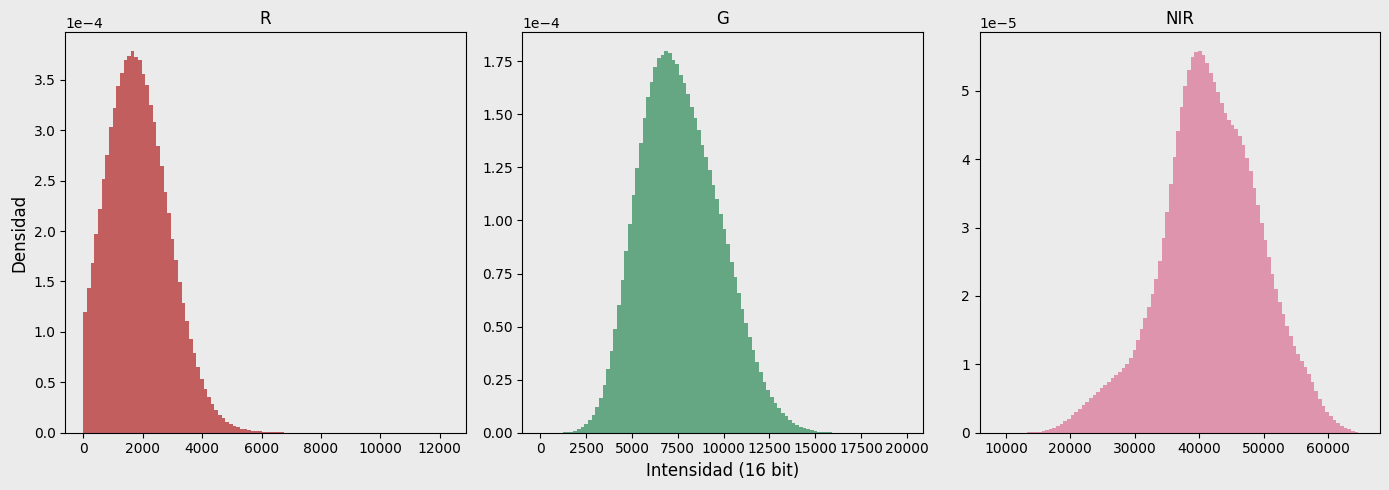

In [52]:
histograma_promedio_bandas(df_hojas)

In [21]:
ctl1 = [h for h in hojas_procesadas if h['plant_id'] == 12 and h['leaf_id'] == 2 and h['dpi']==3]
ctl2 = [h for h in hojas_procesadas if h['plant_id'] == 12 and h['leaf_id'] == 2 and h['dpi']==0]

ctl1

[{'plant_id': 12,
  'leaf_id': 2,
  'batch': 1,
  'date': '24-04',
  'dpi': 3,
  'condition': 'Tratamiento RNA',
  'visual': 'sintomas',
  'sintoma_label': 'sintoma',
  'image_path': '24-04\\Processed_1\\hojas\\P12_h02_24_04.tiff',
  'nir': array([[0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         ...,
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.],
         [0., 0., 0., ..., 0., 0., 0.]], shape=(244, 428)),
  'nir_norm': array([[nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         ...,
         [nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan],
         [nan, nan, nan, ..., nan, nan, nan]], shape=(244, 428)),
  'mask_hoja': array([[False, False, False, ..., False, False, False],
         [False, False, False, ..., False, False, False],
         [False, False, False, ..., 

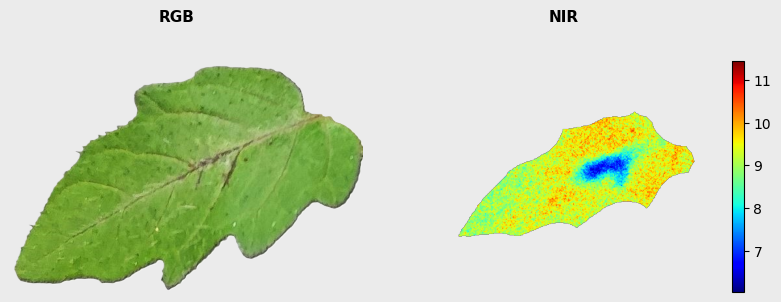

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(10, 10))
fig.patch.set_facecolor('#EBEBEB')


path = r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\24-04\P12_H02_24_04_png.png"

labels = ['RGB','NIR']

foto = mpimg.imread(path)
axs[0].imshow(foto)
axs[0].axis('off')


for hoja in ctl1:
    nir = hoja['nir_norm'].copy()
    mask = hoja['mask_hoja']
    dpi = hoja['dpi']
        
    nir[~mask] = np.nan
    im = axs[1].imshow(nir, cmap='jet')
    axs[1].axis('off')
plt.colorbar(im, ax=axs[1], shrink=0.3)

#axs[0].set_aspect('equal')
#axs[1].set_aspect('equal')
for j, label in enumerate(labels):
    pos = axs[j].get_position()
    fig.text((pos.x0 + pos.width/2)-0.01, 0.65, label, 
         ha='center', fontsize=11, fontweight='bold')
plt.savefig(r'C:\Users\Bruno\Desktop\TESIS\figuras\necrosis_def.png', dpi=350, bbox_inches='tight', facecolor='#EBEBEB')
plt.show()

In [61]:
valor = feats_hojas.loc[
    (feats_hojas['plant_id'] == 12) & 
    (feats_hojas['leaf_id'] == 2) & 
    (feats_hojas['date'] == '25-04'), 
    'std_local_30_p90'
].values[0]

print(valor)

valor = feats_hojas.loc[
    (feats_hojas['plant_id'] == 15) & 
    (feats_hojas['leaf_id'] == 3) & 
    (feats_hojas['date'] == '25-04'), 
    'std_local_30_p90'
].values[0]

print(valor)

1.026624667957263
0.4787134442270146


In [64]:
ctl1 = [h for h in hojas_procesadas if h['plant_id'] == 12 and h['leaf_id'] == 2 and h['dpi']==4]
ctl2 = [h for h in hojas_procesadas if h['plant_id'] == 12 and h['leaf_id'] == 2 and h['dpi']==0]

C:\Users\Bruno\AppData\Local\Temp\ipykernel_15968\2479891280.py:59: RuntimeWarning: divide by zero encountered in divide
  np.sqrt(np.maximum(suma2/count - (suma/count)**2, 0)),
C:\Users\Bruno\AppData\Local\Temp\ipykernel_15968\2479891280.py:59: RuntimeWarning: invalid value encountered in divide
  np.sqrt(np.maximum(suma2/count - (suma/count)**2, 0)),
C:\Users\Bruno\AppData\Local\Temp\ipykernel_15968\2479891280.py:59: RuntimeWarning: invalid value encountered in subtract
  np.sqrt(np.maximum(suma2/count - (suma/count)**2, 0)),
C:\Users\Bruno\AppData\Local\Temp\ipykernel_15968\2479891280.py:82: RuntimeWarning: divide by zero encountered in divide
  np.sqrt(np.maximum(suma2/count - (suma/count)**2, 0)),
C:\Users\Bruno\AppData\Local\Temp\ipykernel_15968\2479891280.py:82: RuntimeWarning: invalid value encountered in divide
  np.sqrt(np.maximum(suma2/count - (suma/count)**2, 0)),
C:\Users\Bruno\AppData\Local\Temp\ipykernel_15968\2479891280.py:82: RuntimeWarning: invalid value encountered i

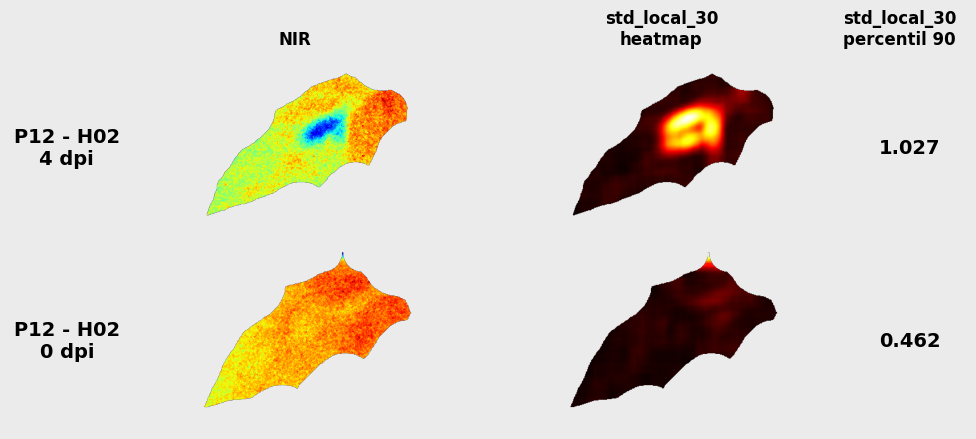

In [68]:
n = 3
fig, axs = plt.subplots(2, 4, figsize=(10, 4),gridspec_kw={'width_ratios': [0.4, 1.3, 1.3, 0.4]})
fig.patch.set_facecolor('#EBEBEB')

from scipy.ndimage import uniform_filter

std1 = feats_hojas.loc[
    (feats_hojas['plant_id'] == 12) & 
    (feats_hojas['leaf_id'] == 2) & 
    (feats_hojas['date'] == '25-04'), 
    'std_local_30_p90'
].values[0].round(3)
std2 = feats_hojas.loc[
    (feats_hojas['plant_id'] == 4) & 
    (feats_hojas['leaf_id'] == 2) & 
    (feats_hojas['date'] == '25-04'), 
    'std_local_30_p90'
].values[0].round(3)


labels = ['NIR','std_local_30\nheatmap', 'std_local_30\npercentil 90']
ventana = 40
label1 = 'P12 - H02\n4 dpi'
label2 = 'P12 - H02\n0 dpi'

axs[0, 0].axis('off')
axs[1, 0].axis('off')
axs[0, 3].axis('off')
axs[1, 3].axis('off')
axs[0, 0].text(0.5, 0.5, label1, transform=axs[0, 0].transAxes,
                    fontsize=14, fontweight='bold', va='center', ha='center')

axs[1, 0].text(0.5, 0.5, label2, transform=axs[1, 0].transAxes,
                    fontsize=14, fontweight='bold', va='center', ha='center')

axs[0, 3].text(0.5, 0.5, std1, transform=axs[0, 3].transAxes,
                    fontsize=14, fontweight='bold', va='center', ha='center')

axs[1, 3].text(0.5, 0.5, std2, transform=axs[1, 3].transAxes,
                    fontsize=14, fontweight='bold', va='center', ha='center')

for hoja in ctl1:
    nir = hoja['nir_norm'].copy()
    mask = hoja['mask_hoja']
    dpi = hoja['dpi']
        
    nir[~mask] = np.nan
    im = axs[0][1].imshow(nir, cmap='jet')
    axs[0][1].axis('off')
#plt.colorbar(im, ax=axs[0], shrink=0.3)

# Calcular mapa de std local
nir_valido = np.where(mask, nir, 0.0)
count = uniform_filter(mask.astype(float), size=ventana)
suma = uniform_filter(nir_valido, size=ventana)
suma2 = uniform_filter(nir_valido**2, size=ventana)

std_local = np.where(count > 0,
                    np.sqrt(np.maximum(suma2/count - (suma/count)**2, 0)),
                    np.nan)
std_local[~mask] = np.nan
axs[0][2].imshow(std_local, cmap='hot')
axs[0][2].axis('off')

for hoja in ctl2:
    nir = hoja['nir_norm'].copy()
    mask = hoja['mask_hoja']
    dpi = hoja['dpi']
        
    nir[~mask] = np.nan
    im = axs[1][1].imshow(nir, cmap='jet')
    axs[1][1].axis('off')
#plt.colorbar(im, ax=axs[0], shrink=0.3)

# Calcular mapa de std local
nir_valido = np.where(mask, nir, 0.0)
count = uniform_filter(mask.astype(float), size=ventana)
suma = uniform_filter(nir_valido, size=ventana)
suma2 = uniform_filter(nir_valido**2, size=ventana)

std_local = np.where(count > 0,
                    np.sqrt(np.maximum(suma2/count - (suma/count)**2, 0)),
                    np.nan)
std_local[~mask] = np.nan
axs[1][2].imshow(std_local, cmap='hot')
axs[1][2].axis('off')

plt.tight_layout()
for j, label in enumerate(labels):
    pos = axs[0][j+1].get_position()
    fig.text((pos.x0 + pos.width/2)-0.01, 1, label, 
         ha='center', fontsize=12, fontweight='bold')
plt.savefig(r'C:\Users\Bruno\Desktop\TESIS\figuras\std_defensa.png', dpi=350, bbox_inches='tight', facecolor='#EBEBEB')
plt.show()

In [6]:
# (path_tiff, nombre_hoja, dpi, path_foto_celular o None)
hojas_inf1 = [
    (r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\21-04\Processed_1\hojas\\P12_h02_21_04.tiff", 'P12-H2', '0dpi', None),
    (r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\22-04\Processed_1\hojas\\P12_h02_22_04.tiff", 'P12-H2', '1dpi', r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\22-04\P12_H02_22_04.jpg"),
    (r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\23-04\Processed_1\hojas\\P12_h02_23_04.tiff", 'P12-H2', '2dpi', r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\23-04\P12_H02_23_04.jpg"),
    (r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\24-04\Processed_1\hojas\\P12_h02_24_04.tiff", 'P12-H2', '3dpi', r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\24-04\P12_H02_24_04.jpg"),
]

hojas_inf2 = [
    (r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\21-04\Processed_1\hojas\\P7_h07_21_04.tiff", 'P7-H7', '0dpi', None),
    (r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\22-04\Processed_1\hojas\\P07_h07_22_04.tiff", 'P7-H7', '1dpi', r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\22-04\P07_H07_22_04.jpg"),
    (r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\23-04\Processed_1\hojas\\P07_h07_23_04.tiff", 'P7-H7', '2dpi', r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\23-04\P07_H07_23_04.jpg"),
    (r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\24-04\Processed_1\hojas\\P07_h07_24_04.tiff", 'P7-H7', '3dpi', r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\24-04\P07_H07_24_04.jpg"),
]

hojas_ctr1 = [
    (r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\21-04\Processed_1\hojas\\P3_h04_21_04.tiff", 'P3-H4', '0dpi', None),
    (r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\22-04\Processed_1\hojas\\P03_h04_22_04.tiff", 'P3-H4', '1dpi', r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\22-04\P03_H04_22_04.jpg"),
    (r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\23-04\Processed_1\hojas\\P03_h04_23_04.tiff", 'P3-H4', '2dpi', r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\23-04\P03_H04_23_04.jpg"),
    (r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\24-04\Processed_1\hojas\\P03_h04_24_04.tiff", 'P3-H4', '3dpi', r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\24-04\P03_H04_24_04.jpg"),
]

In [7]:
dpis = [0,1,2,3]

inf1 = [h for h in hojas_procesadas if h['plant_id'] == 12 and h['leaf_id'] == 2 and h['dpi'] in (dpis)]
inf2 = [h for h in hojas_procesadas if h['plant_id'] == 7 and h['leaf_id'] == 7 and h['dpi'] in (dpis)]
ctl1 = [h for h in hojas_procesadas if h['plant_id'] == 3 and h['leaf_id'] == 4 and h['dpi'] in (dpis)]
print(len(inf1),len(inf2),len(ctl1))

4 4 4


In [8]:
paths_rgb_inf1 = [None, r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\22-04\P12_H02_22_04_png.png", r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\23-04\P12_H02_23_04_png.png", r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\24-04\P12_H02_24_04_png.png"]  # None para dpi 0
paths_rgb_inf2 = [None, r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\22-04\P07_H07_22_04_png.png", r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\23-04\P07_H07_23_04_png.png", r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\24-04\P07_H07_24_04_png.png"]
paths_rgb_ctl1 = [None, r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\22-04\P03_H04_22_04_png.png", r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\23-04\P03_H04_23_04_png.png", r"C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\24-04\P03_H04_24_04_png.png"]

for h, path_rgb in zip(inf1, paths_rgb_inf1):
    h['path_rgb'] = path_rgb
for h, path_rgb in zip(inf2, paths_rgb_inf2):
    h['path_rgb'] = path_rgb
for h, path_rgb in zip(ctl1, paths_rgb_ctl1):
    h['path_rgb'] = path_rgb

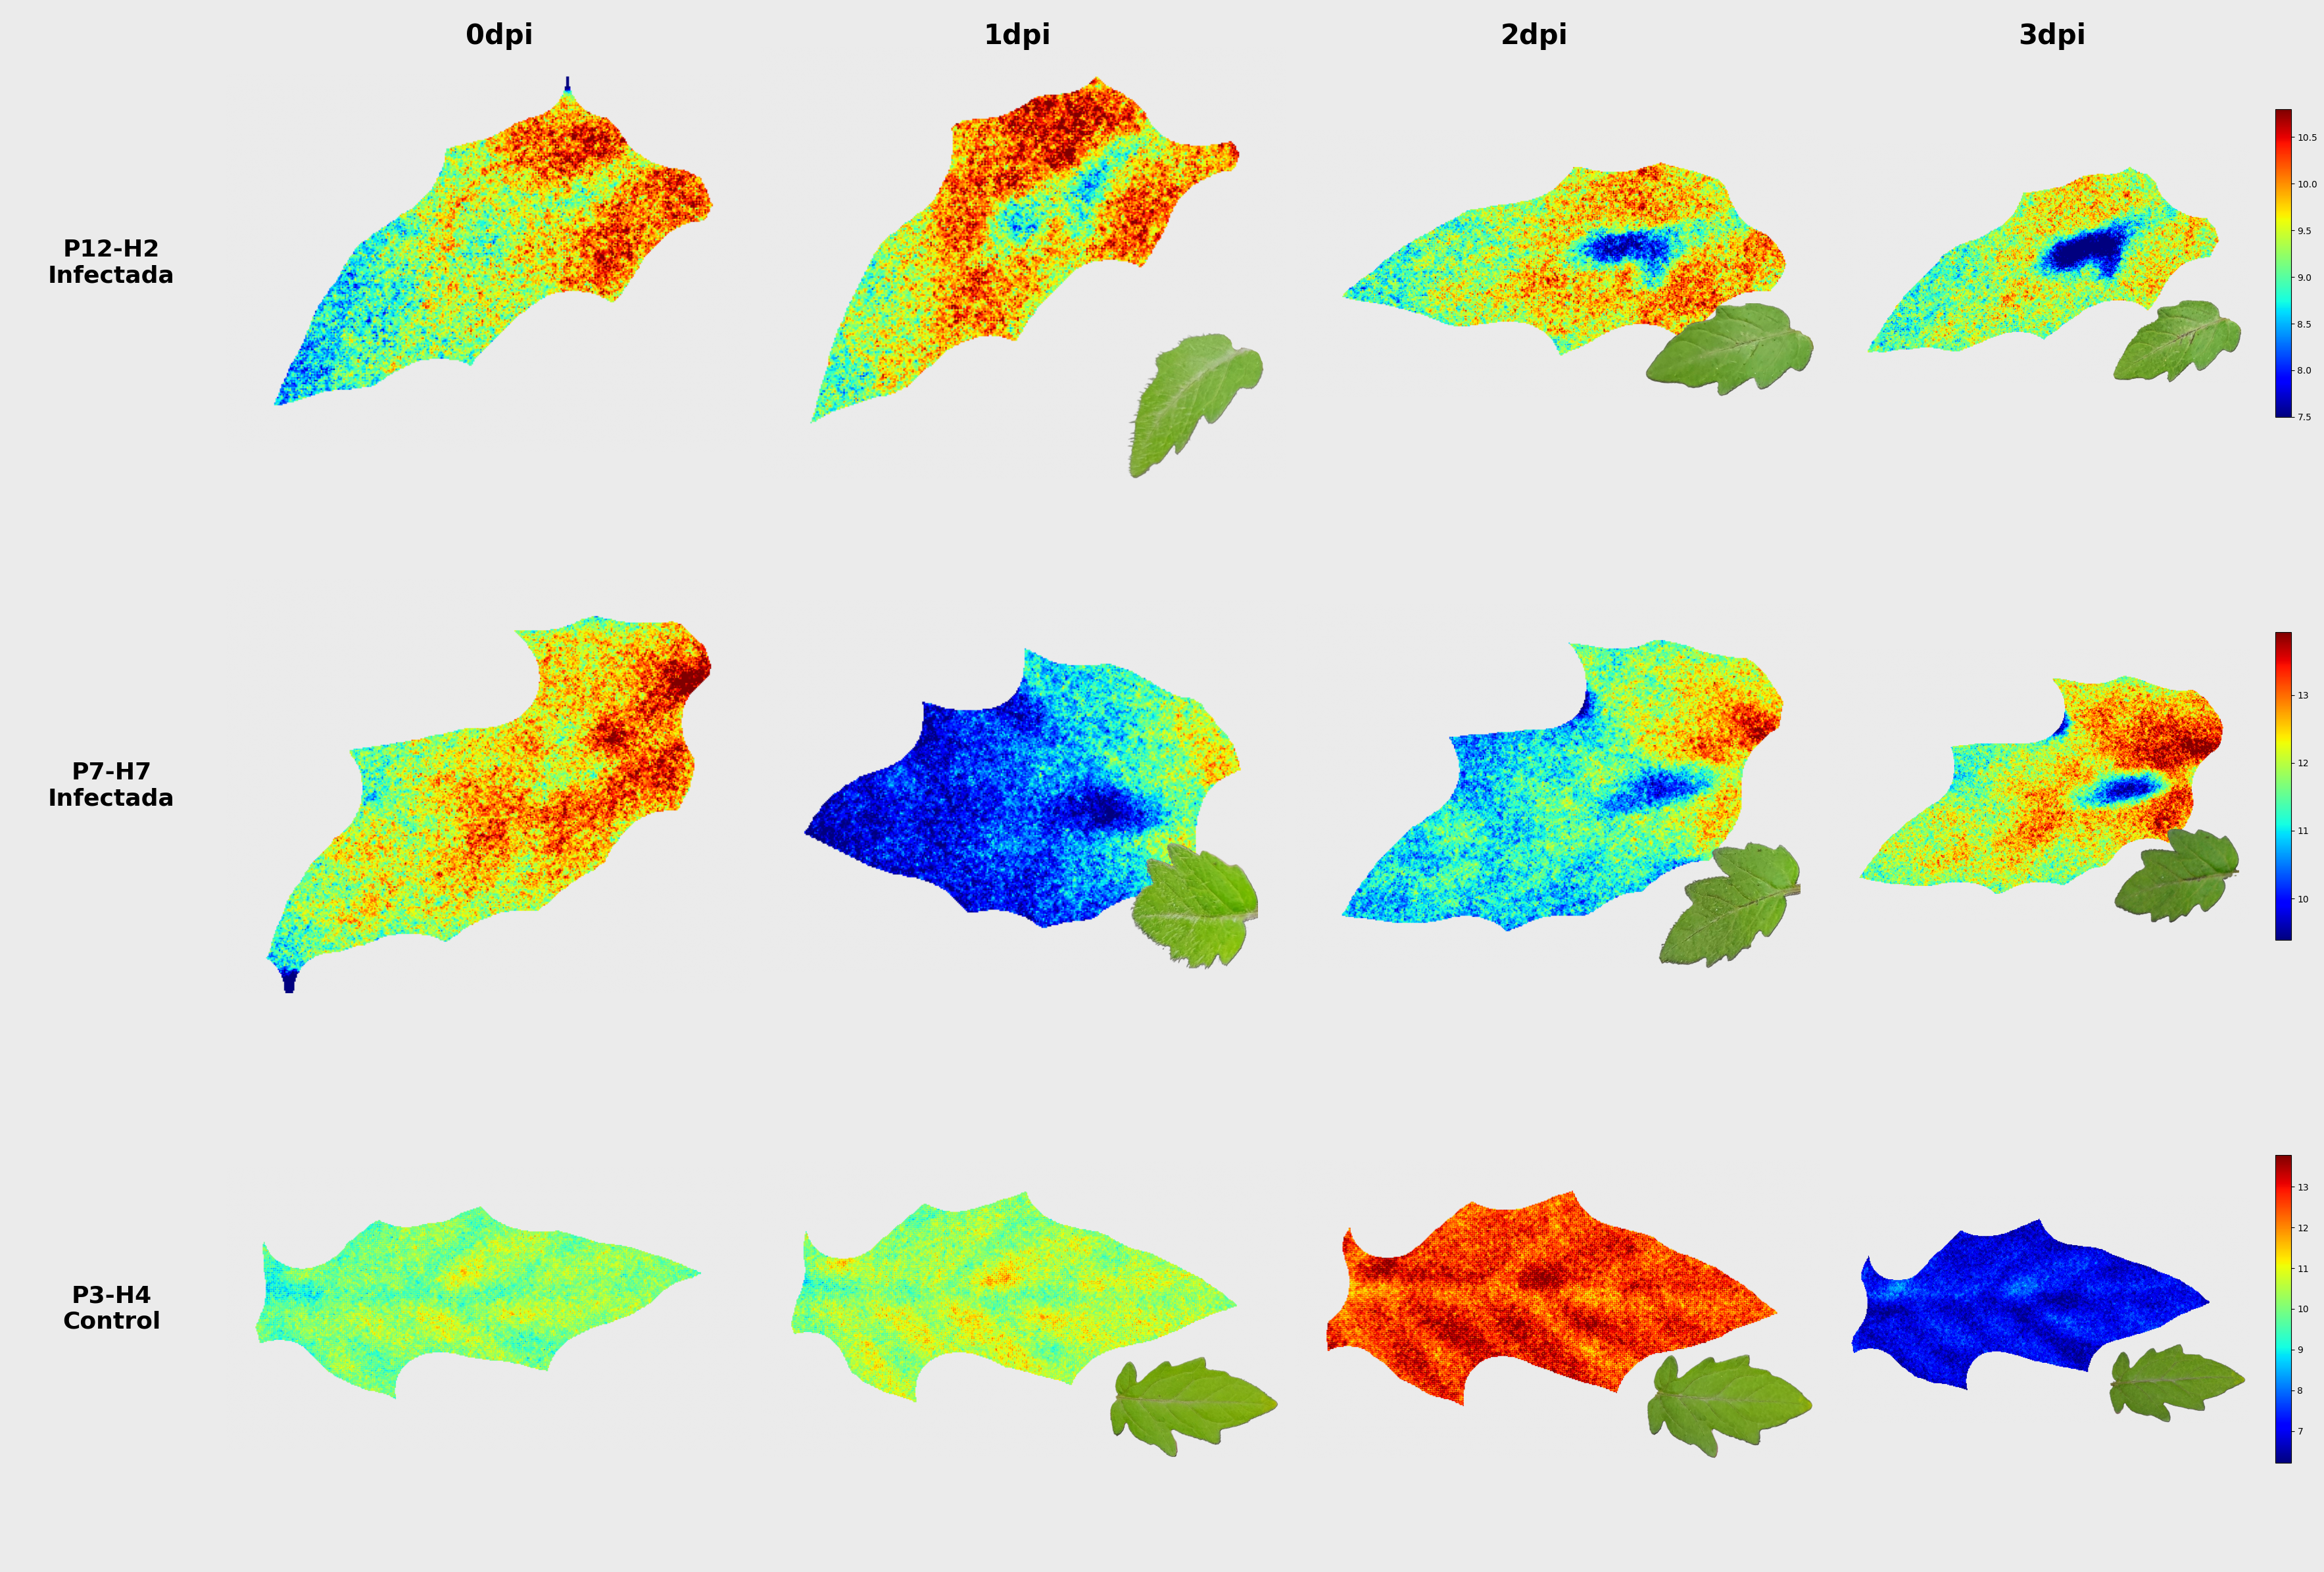

In [10]:
cmap = plt.cm.jet.copy()
cmap.set_bad(color='#EBEBEB')

def calcular_escala(hojas_pro):
    vals = []
    for h in hojas_pro:
        nir = h['nir_norm']
        mask = h['mask_hoja']
        vals.extend(nir[mask].flatten())
    return np.percentile(vals, 1), np.percentile(vals, 99)

grupos = [inf1, inf2, ctl1]
labels = ['P12-H2\nInfectada', 'P7-H7\nInfectada', 'P3-H4\nControl']
n = max(len(g) for g in grupos)
dpi_labels = [h['dpi'] for h in grupos[0]]

fig, axes = plt.subplots(len(grupos), n+1, figsize=(6*(n+2), 24),
                         gridspec_kw={'width_ratios': [0.4] + [1]*n})
fig.patch.set_facecolor('#EBEBEB')

for row, (grupo, label) in enumerate(zip(grupos, labels)):
    axes[row, 0].axis('off')
    axes[row, 0].text(0.5, 0.5, label, transform=axes[row, 0].transAxes,
                      fontsize=26, fontweight='bold', va='center', ha='center')
    
    vmin, vmax = calcular_escala(grupo)
    
    for i, h in enumerate(grupo):
        ax = axes[row, i+1]
        nir = h['nir_norm'].copy()
        mask = h['mask_hoja']
        nir[~mask] = np.nan
        ax.imshow(nir, cmap=cmap, vmin=vmin, vmax=vmax)
        ax.axis('off')
        ax.set_facecolor('#EBEBEB')

        path_rgb = h.get('path_rgb', None)
        if path_rgb is not None:
            foto = mpimg.imread(path_rgb)
            ax_inset = ax.inset_axes([0.65, 0.0, 0.35, 0.35])
            ax_inset.imshow(foto)
            ax_inset.axis('off')

    plt.colorbar(
        plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin, vmax)),
        shrink=0.6,
        ax=axes[row, -1]
    )

for j, dpi in enumerate(dpi_labels):
    pos = axes[0][j+1].get_position()
    fig.text(pos.x0 +(j*0.04) , 0.97, f'{dpi}dpi', 
         ha='center', fontsize=30, fontweight='bold')


plt.tight_layout()
plt.savefig(r'C:\Users\Bruno\Desktop\TESIS\graficos\evolución_comp.png', dpi=300, bbox_inches='tight', facecolor='#EBEBEB')
plt.show()

In [13]:
def plot_feature_por_grupo(df, feature_col,ruta,num, umbrales=[50, 80]):
    
    radio_erosion = 35
    
    df_grupo = df.groupby(['condition', 'dpi'])[feature_col].mean().reset_index()
    colores = {'Control': 'steelblue', 'Infectada': 'firebrick', 'Tratamiento RNA': 'seagreen'}
    
    fig, (ax) = plt.subplots(1, 1, figsize=(12, 4),
                                    sharex=True)
    #fig.patch.set_facecolor('#EBEBEB')
    #ax.set_facecolor('#EBEBEB')
    
    
    for condition, df_condition in df_grupo.groupby('condition'):
        df_condition = df_condition.sort_values('dpi')
        ax.plot(df_condition['dpi'], df_condition[feature_col], marker='o',
                label=condition, color=colores.get(condition, 'gray'))
    
    
    ax.text(-0.1, 0.45, num, transform=ax.transAxes, fontsize=14, fontweight='bold')
    ax.set_xlabel('DPI')
    ax.set_ylabel(feature_col)
    
    ax.legend()
    plt.tight_layout()
    plt.savefig(ruta, dpi=300, bbox_inches='tight')
    plt.show()

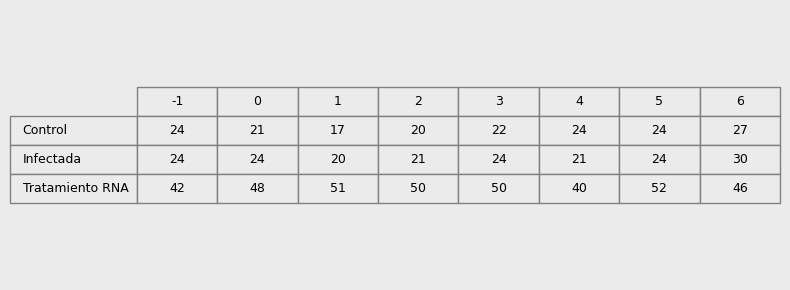

In [11]:
conteo = feats_hojas.groupby(['condition', 'dpi']).size().unstack(fill_value=0)



fig, ax = plt.subplots(figsize=(8, 3))
fig.patch.set_facecolor('#EBEBEB')
ax.set_facecolor('#EBEBEB')
ax.axis('off')

tabla = ax.table(cellText=conteo.values.astype(str),
                rowLabels=conteo.index,
                colLabels=conteo.columns,
                cellLoc='center',
                loc='center')

tabla.auto_set_font_size(False)
tabla.set_fontsize(9)
tabla.scale(1, 1.5)

for key, cell in tabla.get_celld().items():
    cell.set_facecolor('#EBEBEB')
    cell.set_edgecolor('gray')

plt.tight_layout()
plt.show()


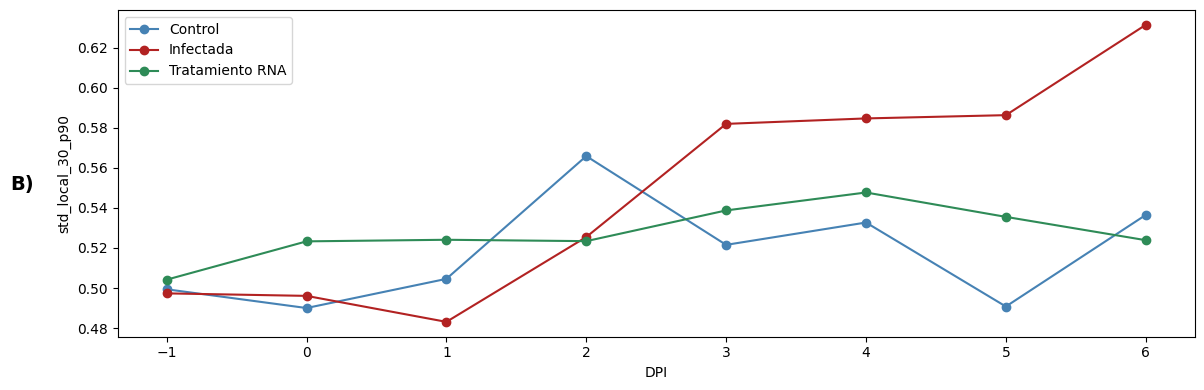

In [14]:
#plot_feature_por_grupo(feats_hojas, "media",num = 'A)', ruta = r'C:\Users\Bruno\Desktop\TESIS\figuras\evolución_media.png')
plot_feature_por_grupo(feats_hojas, "std_local_30_p90",num = 'B)', ruta = r'C:\Users\Bruno\Desktop\TESIS\figuras\evolución_std30_poster.png')
#plot_feature_por_grupo(feats_hojas, "glcm_correlation_mean",num = 'C)', ruta = r'C:\Users\Bruno\Desktop\TESIS\figuras\evolución_glcm.png')
#plot_feature_por_grupo(feats_hojas, "cluster_2_area_mean",num = 'D)', ruta = r'C:\Users\Bruno\Desktop\TESIS\figuras\evolución_clus2.png')


In [ ]:
def plot_feature_por_sintoma(df, feature_col, ruta, umbrales=[30, 50, 80]):
    
    radio_erosion = 35
    
    df_grupo = df.groupby(['sintoma_label', 'dpi'])[feature_col].mean().reset_index()
    colores = {'sintoma': 'firebrick', 'sin_sintoma': 'seagreen'}
    
    fig, ax = plt.subplots(figsize=(12, 5))
    fig.patch.set_facecolor('#94b0e1')
    ax.set_facecolor('#94b0e1')
    
    for condition, df_condition in df_grupo.groupby('sintoma_label'):
        df_condition = df_condition.sort_values('dpi')
        label = 'Control' if condition == 'sin_sintoma' else 'Síntoma'
        ax.plot(df_condition['dpi'], df_condition[feature_col], marker='o',
                label=label, color=colores.get(condition, 'gray'))
    # Umbrales
    df_sintoma = df[df['sintoma_label'] == 'sintoma'].copy()
    total_hojas_sintoma = df_sintoma.groupby(['plant_id', 'leaf_id']).ngroups
    df_sintoma_visual = df_sintoma[df_sintoma['visual'].str.contains('sintoma', na=False)].drop_duplicates(['plant_id', 'leaf_id', 'dpi'])
    conteo_por_dpi = df_sintoma_visual.groupby('dpi').size()
    pct_por_dpi = (conteo_por_dpi / total_hojas_sintoma * 100).reset_index()
    pct_por_dpi.columns = ['dpi', 'pct_sintoma']

    ylim = ax.get_ylim()
    
    colores_umbral = {30:'black', 50: 'black', 80: 'black'}
    for umbral in umbrales:
        dpi_umbral = pct_por_dpi[pct_por_dpi['pct_sintoma'] >= umbral]['dpi'].min()
        if not np.isnan(dpi_umbral):
            ax.axvline(x=dpi_umbral, color=colores_umbral.get(umbral, 'gray'),
                      linestyle='--', linewidth=1.5, alpha=0.7)
            ax.text(dpi_umbral + 0.05, ylim[1] * 0.98, f'{umbral}%\nsíntoma',
                   color=colores_umbral.get(umbral, 'gray'), fontsize=7, va='top')
    
    # Tabla de conteos
    conteo = df.groupby(['sintoma_label', 'dpi']).size().unstack(fill_value=0).sort_index(axis=1)
    tabla_data = [[str(v) for v in conteo.loc[label]] for label in conteo.index]
    col_labels = [str(d) for d in conteo.columns]
    row_labels = list(conteo.index)

    tabla = ax.table(cellText=tabla_data,
                    rowLabels=row_labels,
                    colLabels=col_labels,
                    cellLoc='center',
                    loc='bottom',
                    bbox=[0, -0.35, 1, 0.2])
    tabla.auto_set_font_size(False)
    tabla.set_fontsize(8)

    for key, cell in tabla.get_celld().items():
        cell.set_facecolor('#94b0e1')
        cell.set_edgecolor('gray')
        if key[0] == 0:
            cell.set_visible(False)

    ax.set_ylabel(feature_col)

    legend = ax.legend()
    legend.get_frame().set_facecolor('#94b0e1')
    legend.get_frame().set_edgecolor('#94b0e1')
    plt.subplots_adjust(bottom=0.25)
    plt.tight_layout()
    plt.savefig(ruta, dpi=350, bbox_inches='tight')
    plt.show()

In [8]:
from scipy.stats import mannwhitneyu
def test_por_dpi(df, feature_col, grupo_a=['Infectada'], grupos_b=['Control']):
    
    resultados = []
    for dpi, df_dpi in df.groupby('dpi'):
        a = df_dpi[df_dpi['sintoma_label']=='sintoma'][feature_col]
        b = df_dpi[df_dpi['condition'].isin(grupos_b)][feature_col]
        
        if len(a) < 3 or len(b) < 3:
            continue
        
        stat, p = mannwhitneyu(a, b, alternative='two-sided')
        resultados.append({
            'dpi': dpi,
            'n_infectada': len(a),
            'n_control': len(b),
            'p_valor': round(p, 4),
            'significativo': p < 0.05
        })
    
    return pd.DataFrame(resultados).sort_values('dpi')

In [11]:
def plot_feature_por_sintoma(df, feature_col, ruta, umbrales=[30, 50, 80]):
    
    df_grupo = df.groupby(['sintoma_label', 'dpi'])[feature_col].mean().reset_index()
    colores = {'sintoma': 'firebrick', 'sin_sintoma': 'seagreen'}
    
    fig, (ax, ax_p) = plt.subplots(2, 1, figsize=(12, 5),
                                    gridspec_kw={'height_ratios': [5, 1]},
                                    sharex=True)
    #fig.patch.set_facecolor('#EBEBEB')
    #ax.set_facecolor('#EBEBEB')
    #ax_p.set_facecolor('#EBEBEB')
    
    for condition, df_condition in df_grupo.groupby('sintoma_label'):
        df_condition = df_condition.sort_values('dpi')
        label = 'Control' if condition == 'sin_sintoma' else 'Síntoma'
        ax.plot(df_condition['dpi'], df_condition[feature_col], marker='o',
                label=label, color=colores.get(condition, 'gray'))

    # Umbrales
    df_sintoma = df[df['sintoma_label'] == 'sintoma'].copy()
    total_hojas_sintoma = df_sintoma.groupby(['plant_id', 'leaf_id']).ngroups
    df_sintoma_visual = df_sintoma[df_sintoma['visual'].str.contains('sintoma', na=False)].drop_duplicates(['plant_id', 'leaf_id', 'dpi'])
    conteo_por_dpi = df_sintoma_visual.groupby('dpi').size()
    pct_por_dpi = (conteo_por_dpi / total_hojas_sintoma * 100).reset_index()
    pct_por_dpi.columns = ['dpi', 'pct_sintoma']

    ylim = ax.get_ylim()
    colores_umbral = {30: 'black', 50: 'black', 80: 'black'}
    for umbral in umbrales:
        dpi_umbral = pct_por_dpi[pct_por_dpi['pct_sintoma'] >= umbral]['dpi'].min()
        if not np.isnan(dpi_umbral):
            ax.axvline(x=dpi_umbral, color=colores_umbral.get(umbral, 'gray'),
                      linestyle='--', linewidth=1.5, alpha=0.7)
            ax.text(dpi_umbral + 0.05, ylim[1] * 0.98, f'{umbral}%\nsíntoma',
                   color=colores_umbral.get(umbral, 'gray'), fontsize=10, va='top')

    # P-valores
    df_tests = test_por_dpi(df, feature_col)
    dpis = df_tests['dpi'].values
    pvals = df_tests['p_valor'].values

    ax_p.plot(dpis, pvals, marker='o', color='firebrick', linewidth=1)
    ax_p.axhline(y=0.05, color='black', linestyle='--', linewidth=1, alpha=0.7)
    ax_p.text(dpis[-1] + 0.05, 0.05, 'p=0.05', fontsize=10, va='center')
    ax_p.set_ylabel('p-valor', fontsize=10)
    ax_p.set_xlabel('DPI', fontsize=16)
    ax_p.set_ylim(0, max(pvals.max() * 1.1, 0.15))
    ax.tick_params(labelsize=14) 
    ax_p.tick_params(labelsize=14)   
    ax.set_ylabel(feature_col)
    legend = ax.legend(fontsize = 12)
    #legend.get_frame().set_facecolor('#EBEBEB')
    #legend.get_frame().set_edgecolor('#EBEBEB')

    plt.tight_layout()
    plt.savefig(ruta, dpi=350, bbox_inches='tight')
    plt.show()

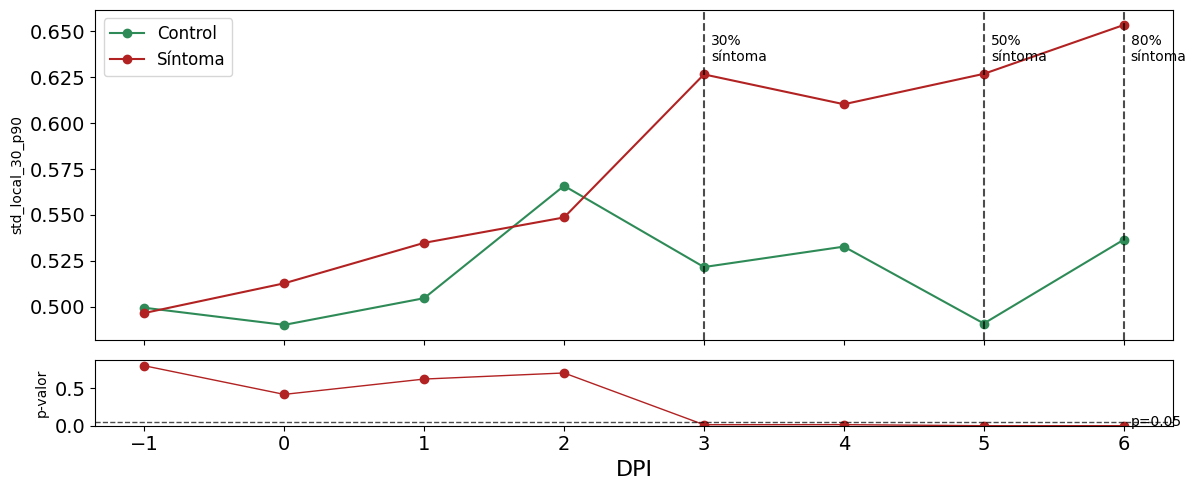

In [12]:
feats_sintomas = feats_hojas[(feats_hojas['condition']=='Control') | (feats_hojas['sintoma_label']=='sintoma')]
plot_feature_por_sintoma(feats_sintomas, "std_local_30_p90", ruta = r'C:\Users\Bruno\Desktop\TESIS\figuras\std_sintoma_pval_defensa.png')

In [6]:
from scipy.stats import mannwhitneyu

def plot_feature_por_sintoma(df, feature_col, ruta, umbrales=[30, 50, 80]):

    df = df.copy()
    # Marca si la hoja tiene síntoma visible en ESE dpi puntual (no acumulado)
    df['visible_ese_dpi'] = df['visual'].str.contains('sintoma', na=False)

    # --- Curva Control (sin cambios) ---
    df_control = df[df['sintoma_label'] == 'sin_sintoma']
    media_control = df_control.groupby('dpi')[feature_col].mean().reset_index()

    # --- Grupo síntoma, separado en dos subgrupos por dpi ---
    df_sintoma = df[df['sintoma_label'] == 'sintoma'].copy()

    df_visible = df_sintoma[df_sintoma['visible_ese_dpi']]
    df_no_visible = df_sintoma[~df_sintoma['visible_ese_dpi']]

    media_visible = df_visible.groupby('dpi')[feature_col].mean().reset_index()
    media_no_visible = df_no_visible.groupby('dpi')[feature_col].mean().reset_index()

    fig, (ax, ax_p) = plt.subplots(2, 1, figsize=(12, 5.5),
                                    gridspec_kw={'height_ratios': [5, 1.4]},
                                    sharex=True)

    ax.plot(media_control['dpi'], media_control[feature_col], marker='o',
            label='Control', color='seagreen', linewidth=2)

    ax.plot(media_no_visible['dpi'], media_no_visible[feature_col], marker='o',
            label='Síntoma — aún no visible', color='darkorange',
            linewidth=2, linestyle='--')

    ax.plot(media_visible['dpi'], media_visible[feature_col], marker='o',
            label='Síntoma — visible', color='firebrick', linewidth=2)

    # --- Umbrales de % de hojas con síntoma visible (idéntico a lo que ya tenías) ---
    total_hojas_sintoma = df_sintoma.groupby(['plant_id', 'leaf_id']).ngroups
    df_sintoma_visual = df_visible.drop_duplicates(['plant_id', 'leaf_id', 'dpi'])
    conteo_por_dpi = df_sintoma_visual.groupby('dpi').size()
    pct_por_dpi = (conteo_por_dpi / total_hojas_sintoma * 100).reset_index()
    pct_por_dpi.columns = ['dpi', 'pct_sintoma']

    ylim = ax.get_ylim()
    colores_umbral = {30: 'black', 50: 'black', 80: 'black'}
    for umbral in umbrales:
        dpi_umbral = pct_por_dpi[pct_por_dpi['pct_sintoma'] >= umbral]['dpi'].min()
        if not np.isnan(dpi_umbral):
            ax.axvline(x=dpi_umbral, color=colores_umbral.get(umbral, 'gray'),
                      linestyle=':', linewidth=1.2, alpha=0.6)
            ax.text(dpi_umbral + 0.05, ylim[1] * 0.98, f'{umbral}%\nsíntoma',
                   color=colores_umbral.get(umbral, 'gray'), fontsize=9, va='top')

    # --- P-valores: Síntoma completo vs Control (el que ya tenías) ---
    df_tests = test_por_dpi(df, feature_col)
    dpis = df_tests['dpi'].values
    pvals = df_tests['p_valor'].values

    # --- P-valor extra: subgrupo "aún no visible" vs Control ---
    dpis_extra, pvals_extra = [], []
    for dpi in sorted(df['dpi'].unique()):
        grupo_a = df_no_visible[df_no_visible['dpi'] == dpi][feature_col].dropna()
        grupo_b = df_control[df_control['dpi'] == dpi][feature_col].dropna()
        if len(grupo_a) >= 3 and len(grupo_b) >= 3:  # n mínimo para que el test tenga sentido
            _, p = mannwhitneyu(grupo_a, grupo_b, alternative='two-sided')
            dpis_extra.append(dpi)
            pvals_extra.append(p)

    ax_p.plot(dpis, pvals, marker='o', color='firebrick', linewidth=1,
              label='Síntoma (completo) vs Control')
    if pvals_extra:
        ax_p.plot(dpis_extra, pvals_extra, marker='o', color='darkorange', linewidth=1,
                  linestyle='--', label='Aún no visible vs Control')
    ax_p.axhline(y=0.05, color='black', linestyle='--', linewidth=1, alpha=0.7)
    ax_p.text(dpis[-1] + 0.05, 0.05, 'p=0.05', fontsize=10, va='center')
    ax_p.set_ylabel('p-valor', fontsize=10)
    ax_p.set_xlabel('DPI', fontsize=16)
    max_p = max(pvals.max(), max(pvals_extra) if pvals_extra else 0)
    ax_p.set_ylim(0, max(max_p * 1.1, 0.15))
    ax_p.legend(fontsize=8, loc='upper right')

    ax.tick_params(labelsize=14)
    ax_p.tick_params(labelsize=14)
    ax.set_ylabel(feature_col)
    ax.legend(fontsize=11)

    plt.tight_layout()
    plt.savefig(ruta, dpi=350, bbox_inches='tight')
    plt.show()

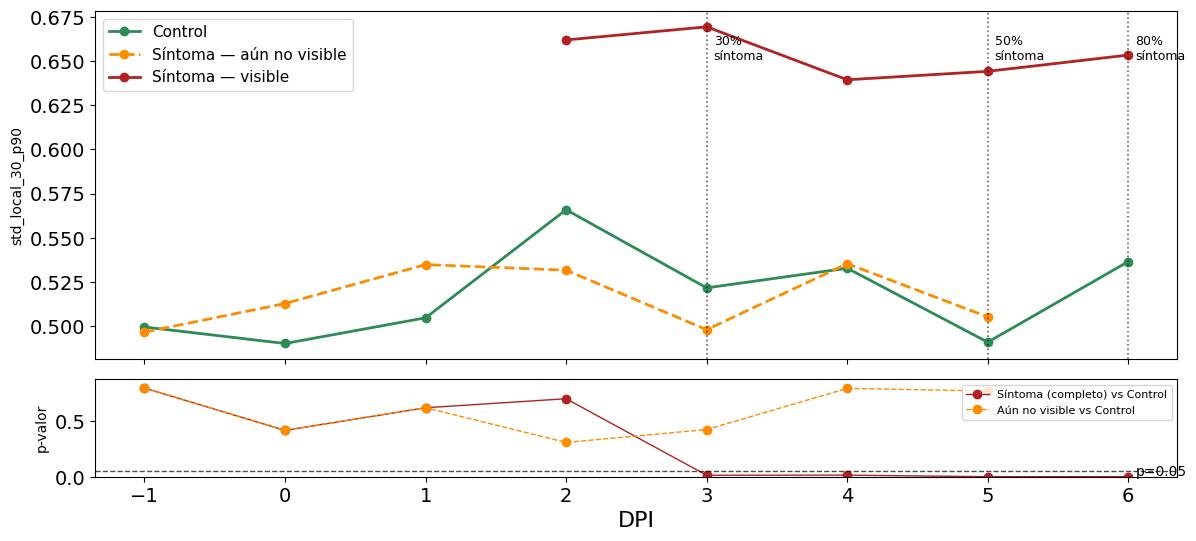

In [9]:
feats_sintomas = feats_hojas[(feats_hojas['condition']=='Control') | (feats_hojas['sintoma_label']=='sintoma')]
plot_feature_por_sintoma(feats_sintomas, "std_local_30_p90", ruta = r'C:\Users\Bruno\Desktop\TESIS\figuras\std_sintoma_pval_defensa.png')

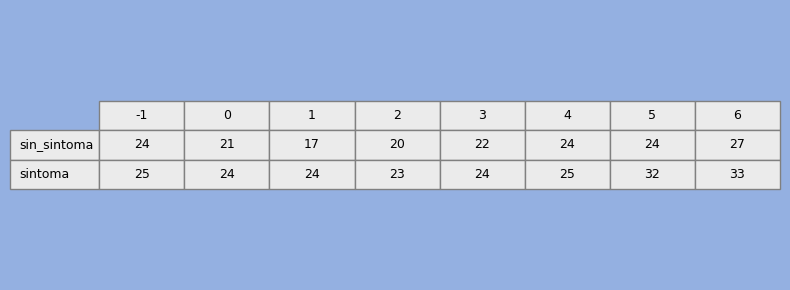

In [11]:
feats_sintomas = feats_hojas[(feats_hojas['condition']=='Control') | (feats_hojas['sintoma_label']=='sintoma')]
cant = feats_sintomas.groupby([ 'sintoma_label', 'dpi']).size().unstack(fill_value=0)



fig, ax = plt.subplots(figsize=(8, 3))
fig.patch.set_facecolor('#94b0e1')
ax.set_facecolor('#94b0e1')
ax.axis('off')

tabla = ax.table(cellText=cant.values.astype(str),
                rowLabels=cant.index,
                colLabels=cant.columns,
                cellLoc='center',
                loc='center')

tabla.auto_set_font_size(False)
tabla.set_fontsize(9)
tabla.scale(1, 1.5)

for key, cell in tabla.get_celld().items():
    cell.set_facecolor('#EBEBEB')
    cell.set_edgecolor('gray')

plt.tight_layout()
plt.show()


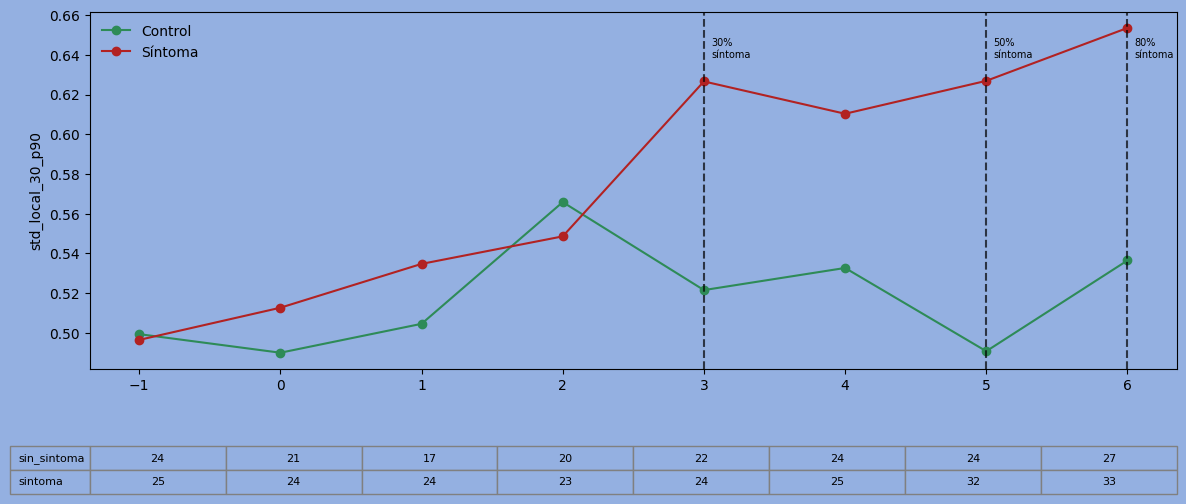

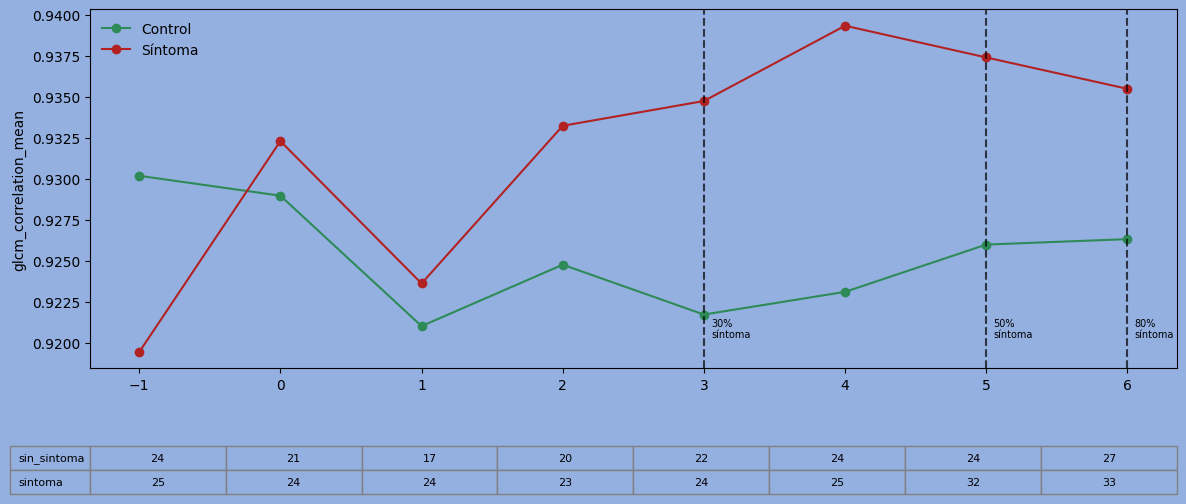

In [20]:


plot_feature_por_sintoma(feats_sintomas, "std_local_30_p90", ruta = r'C:\Users\Bruno\Desktop\TESIS\figuras\std_sintoma_poster.png')
plot_feature_por_sintoma(feats_sintomas, "glcm_correlation_mean", ruta = r'C:\Users\Bruno\Desktop\TESIS\figuras\glcm_sintoma.png')

In [13]:
features = [
    'media', 'std', 'iqr', 'skewness', 'entropia',
    'prop_afectada_2',
    'std_local_30_mean', 'std_local_30_p90',
    'std_local_50_mean', 'std_local_50_p90',
    'gradiente_mean', 'gradiente_p90', 'gradiente_std',
    'glcm_contrast_mean', 'glcm_contrast_std',
    'glcm_energy_mean', 'glcm_energy_std',
    'glcm_correlation_mean', 'glcm_correlation_std',
    'gabor_freq0.1_mean',
    'gabor_freq0.3_mean',
    'cluster_1_n', 'cluster_1_area_max', 'cluster_1_area_mean',
    'cluster_2_n', 'cluster_2_area_max', 'cluster_2_area_mean',
]

feature = ['std_local_30_p90']

In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, confusion_matrix
from imblearn.over_sampling import SMOTE
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.svm import SVC

In [15]:
def preparar_dataset(df, etiqueta_col='visual'):
    df = df.copy()
    
    df['target'] = df[etiqueta_col].str.contains('sintoma', na=False).astype(int)
    
    hojas_con_sintoma_set = set(
        zip(df[df['target'] == 1]['plant_id'],
            df[df['target'] == 1]['leaf_id'])
    )
    
    instancias_con_sintoma = set(
        zip(df[df['target'] == 1]['plant_id'],
            df[df['target'] == 1]['leaf_id'],
            df[df['target'] == 1]['dpi'])
    )
    
    def filtrar_fila(row):
        es_hoja_con_sintoma = (row['plant_id'], row['leaf_id']) in hojas_con_sintoma_set
        if es_hoja_con_sintoma:
            return (row['plant_id'], row['leaf_id'], row['dpi']) in instancias_con_sintoma
        else:
            return True
    
    mask = df.apply(filtrar_fila, axis=1)
    df = df[mask].copy()
    
    return df


def rf_lopo_pareado(df, features, etiqueta_col='visual', umbral=0.5,
                    pesos=None, usar_smote=False, sampleo = 1.0, nombre_archivo='reporte_rf.png'):
    
    df_full = df.copy()
    df_full['target'] = df_full[etiqueta_col].str.contains('sintoma', na=False).astype(int)

    
    folds = [
        (1, 6), (2, 7), (3, 8), (4, 9), (5, 10),
        (11, 12), (13, 14), (15, 16), (17, 18), (19, 20)
    ]
    
    n_pos_global = int(df_full['target'].sum())
    n_neg_global = int((df_full['target'] == 0).sum())
    
    y_real_total = []
    y_pred_total = []
    y_proba_total = []
    dpi_total = []
    importancias = []
    plant_id_total = []
    leaf_id_total = []
    condition_total = []

    for fold_idx, (p1, p2) in enumerate(folds, 1):
        
        plantas_test = [p1, p2]
        mask_test = df_full['plant_id'].isin(plantas_test)
        mask_train = ~mask_test

        df_train = preparar_dataset(df_full[mask_train], etiqueta_col)
        X_train = df_train[features]
        y_train = df_train['target']

        X_test = df_full.loc[mask_test, features]
        y_test = df_full.loc[mask_test, 'target']
        
        if y_train.nunique() < 2 or y_test.nunique() < 2:
            print(f'Fold {fold_idx} ({p1},{p2}): clases insuficientes, salteando')
            continue
        
        if usar_smote:
            sm = SMOTE(random_state=42, sampling_strategy= sampleo)
            X_train, y_train = sm.fit_resample(X_train, y_train)
        
        rf = RandomForestClassifier(n_estimators=100, random_state=42)
        rf.fit(X_train, y_train)


        #scaler = StandardScaler()
        #X_train = scaler.fit_transform(X_train)
        #X_test = scaler.transform(X_test)

        #svm = SVC(C=100, gamma='scale', kernel='rbf', class_weight='balanced', probability=True, random_state=42)
        #svm.fit(X_train, y_train)
        
        y_proba_test = rf.predict_proba(X_test)[:, 1]
        y_pred_test = (y_proba_test >= umbral).astype(int)
        
        y_real_total.extend(y_test.tolist())
        y_pred_total.extend(y_pred_test.tolist())
        y_proba_total.extend(y_proba_test.tolist())
        importancias.append(rf.feature_importances_)
        dpi_total.extend(df_full.loc[mask_test, 'dpi'].tolist())
        plant_id_total.extend(df_full.loc[mask_test, 'plant_id'].tolist())
        leaf_id_total.extend(df_full.loc[mask_test, 'leaf_id'].tolist())
        condition_total.extend(df_full.loc[mask_test, 'condition'].tolist())
    
    # Top 3 features
    imp_media = np.mean(importancias, axis=0)
    top3_idx = np.argsort(imp_media)[::-1][:3]
    top3 = [f'{features[i]} ({imp_media[i]:.3f})' for i in top3_idx]
    
    # Metricas por dpi
    df_preds = pd.DataFrame({
        'y_real': y_real_total,
        'y_pred': y_pred_total,
        'y_proba': y_proba_total,
        'dpi': dpi_total,
        'plant_id': plant_id_total,
        'leaf_id': leaf_id_total,
        'condition': condition_total
    })
    
    resultados_dpi = []
    matrices_cm = {}
    histogramas = {}
    
    for dpi, df_dpi in df_preds.groupby('dpi'):
        acc = accuracy_score(df_dpi['y_real'], df_dpi['y_pred'])
        f1 = f1_score(df_dpi['y_real'], df_dpi['y_pred'], average='weighted')
        recall = recall_score(df_dpi['y_real'], df_dpi['y_pred'])
        all_labels = [0,1]
        cm = confusion_matrix(df_dpi['y_real'], df_dpi['y_pred'], labels= all_labels)
        n_pos = int(df_dpi['y_real'].sum())
        n_neg = int((df_dpi['y_real'] == 0).sum())
        
        resultados_dpi.append({
            'dpi': dpi,
            'acc': round(acc, 3),
            'recall': round(recall, 3),
            'f1': round(f1, 3),
            'n_pos': n_pos,
            'n_neg': n_neg,
        })
        
        matrices_cm[dpi] = cm
        histogramas[dpi] = (
            df_dpi.loc[df_dpi['y_real'] == 0, 'y_proba'].values,
            df_dpi.loc[df_dpi['y_real'] == 1, 'y_proba'].values
        )
    
    df_dpi_result = pd.DataFrame(resultados_dpi).sort_values('dpi')
    
    # Config para el reporte
    config = {
        'tipo': 'Random Forest',
        'etiqueta': etiqueta_col,
        'umbral': umbral,
        'pesos': str(pesos) if pesos else 'default',
        'smote': 'Si' if usar_smote else 'No',
        'sampleo': sampleo if usar_smote else '0',
        'cv': '10 folds LOPO pareado',
        'n_pos': n_pos_global,
        'n_neg': n_neg_global,
        'top3': ' | '.join(top3)
    }
    
    
    
    return df_dpi_result, df_preds, top3

In [20]:
df_dpi_result_unico, df_preds_unico, top3_unico = rf_lopo_pareado(feats_hojas, features=feature, umbral=0.3,
                           usar_smote=False, sampleo=0.3, nombre_archivo='rf_un_f.png')

c:\Users\Bruno\Desktop\TESIS\segmentador\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Bruno\Desktop\TESIS\segmentador\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Bruno\Desktop\TESIS\segmentador\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [21]:
df_tabla = df_dpi_result_unico.rename(columns={
    'dpi': 'DPI',
    'acc': 'Accuracy',
    'recall': 'Recall',
    'f1': 'F1-score',
    'n_pos': '$n_{pos}$',
    'n_neg': '$n_{neg}$'
})

print(df_tabla.to_latex(index=False, float_format="%.3f", escape=False))

\begin{tabular}{rrrrrr}
\toprule
DPI & Accuracy & Recall & F1-score & $n_{pos}$ & $n_{neg}$ \\
\midrule
-1 & 0.933 & 0.000 & 0.966 & 0 & 90 \\
0 & 0.903 & 0.000 & 0.949 & 0 & 93 \\
1 & 0.920 & 0.000 & 0.959 & 0 & 88 \\
2 & 0.802 & 0.667 & 0.864 & 3 & 88 \\
3 & 0.812 & 0.500 & 0.812 & 18 & 78 \\
4 & 0.753 & 0.333 & 0.744 & 18 & 67 \\
5 & 0.760 & 0.464 & 0.750 & 28 & 72 \\
6 & 0.738 & 0.576 & 0.737 & 33 & 70 \\
\bottomrule
\end{tabular}



In [19]:
svm_dpi_result, svm_preds = rf_lopo_pareado(feats_hojas, features=features, umbral=0.4,
                           usar_smote=False, sampleo=0.3, nombre_archivo='rf.png')

c:\Users\Bruno\Desktop\TESIS\segmentador\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Bruno\Desktop\TESIS\segmentador\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Bruno\Desktop\TESIS\segmentador\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


ValueError: too many values to unpack (expected 2)

In [20]:
df_tabla = svm_dpi_result.rename(columns={
    'dpi': 'DPI',
    'acc': 'Accuracy',
    'recall': 'Recall',
    'f1': 'F1-score',
    'n_pos': '$n_{pos}$',
    'n_neg': '$n_{neg}$'
})

print(df_tabla.to_latex(index=False, float_format="%.3f", escape=False))

NameError: name 'svm_dpi_result' is not defined

In [16]:
df_dpi_result, df_preds, top3 = rf_lopo_pareado(feats_hojas, features=features, umbral=0.3,
                           usar_smote=False, sampleo=0.3, nombre_archivo='rf.png')

c:\Users\Bruno\Desktop\TESIS\segmentador\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Bruno\Desktop\TESIS\segmentador\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Bruno\Desktop\TESIS\segmentador\venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 due to no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [17]:
df_preds['fase'] = df_preds['dpi'].apply(lambda x: 'pre-síntoma' if x <= 1 else 'post-síntoma')

resultados_fase = []
for fase, df_fase in df_preds.groupby('fase'):
    acc = accuracy_score(df_fase['y_real'], df_fase['y_pred'])
    n_pos = int(df_fase['y_real'].sum())
    n_neg = int((df_fase['y_real'] == 0).sum())
    
    if n_pos > 0:
        recall = recall_score(df_fase['y_real'], df_fase['y_pred'])
        f1 = f1_score(df_fase['y_real'], df_fase['y_pred'], average='weighted')
    else:
        recall = None
        f1 = None
    
    # Falsos positivos sobre negativos reales
    fp = ((df_fase['y_real'] == 0) & (df_fase['y_pred'] == 1)).sum()
    fpr = fp / n_neg if n_neg > 0 else None
    
    resultados_fase.append({
        'fase': fase, 'acc': acc, 'recall': recall, 'f1': f1,
        'fpr': fpr, 'n_pos': n_pos, 'n_neg': n_neg
    })

df_fase_result = pd.DataFrame(resultados_fase)

In [26]:
print(df_fase_result.to_string(index=False, float_format='%.3f'))

        fase   acc  recall    f1   fpr  n_pos  n_neg
post-síntoma 0.851   0.630 0.850 0.091    100    375
 pre-síntoma 0.930     NaN   NaN 0.070      0    271


In [23]:
print(top3)

['std_local_50_p90 (0.240)', 'std_local_30_p90 (0.103)', 'skewness (0.066)']


In [35]:
df_tabla = df_dpi_result.rename(columns={
    'dpi': 'DPI',
    'acc': 'Accuracy',
    'recall': 'Recall',
    'f1': 'F1-score',
    'n_pos': '$n_{pos}$',
    'n_neg': '$n_{neg}$'
})

print(df_tabla.to_latex(index=False, float_format="%.3f", escape=False))

\begin{tabular}{rrrrrr}
\toprule
DPI & Accuracy & Recall & F1-score & $n_{pos}$ & $n_{neg}$ \\
\midrule
-1 & 0.967 & 0.000 & 0.983 & 0 & 90 \\
0 & 0.914 & 0.000 & 0.955 & 0 & 93 \\
1 & 0.909 & 0.000 & 0.952 & 0 & 88 \\
2 & 0.901 & 1.000 & 0.928 & 3 & 88 \\
3 & 0.865 & 0.556 & 0.860 & 18 & 78 \\
4 & 0.859 & 0.722 & 0.861 & 18 & 67 \\
5 & 0.870 & 0.607 & 0.861 & 28 & 72 \\
6 & 0.767 & 0.606 & 0.765 & 33 & 70 \\
\bottomrule
\end{tabular}



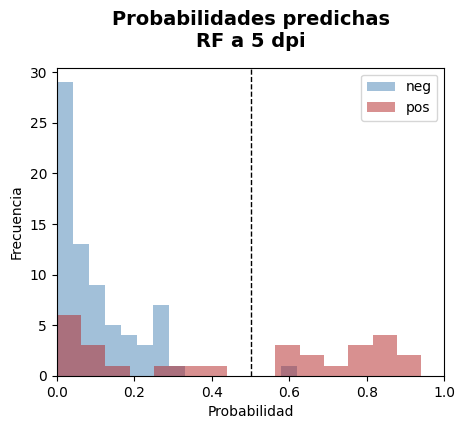

In [19]:
import matplotlib.pyplot as plt

dpis_a_mostrar = [5]
letras = ['a']

for dpi, letra in zip(dpis_a_mostrar, letras):
    df_dpi = df_preds[df_preds['dpi'] == dpi]
    
    proba_neg = df_dpi.loc[df_dpi['y_real'] == 0, 'y_proba'].values
    proba_pos = df_dpi.loc[df_dpi['y_real'] == 1, 'y_proba'].values
    
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.hist(proba_neg, bins=15, alpha=0.5, color='steelblue', label='neg')
    ax.hist(proba_pos, bins=15, alpha=0.5, color='firebrick', label='pos')
    ax.axvline(x=0.5, color='black', linestyle='--', linewidth=1)
    ax.set_xlim(0, 1)
    ax.set_xlabel('Probabilidad')
    ax.set_ylabel('Frecuencia')
    ax.set_title(f"Probabilidades predichas\nRF a {dpi} dpi", fontsize=14, fontweight='bold', pad=15)
    ax.legend()
    
    plt.savefig(r'C:\Users\Bruno\Desktop\TESIS\figuras\hist_probas_defensa.png', dpi=300, bbox_inches='tight')
    plt.show()

In [12]:
import matplotlib.gridspec as gridspec
from PIL import Image
def predicciones_erradas(ejemplos, df_preds, hojas_procesadas, nombre_archivo='figura_tesis.png'):

    n = len(ejemplos)
    
    for ej in ejemplos:
        match = df_preds[
            (df_preds['plant_id'] == ej['plant_id']) &
            (df_preds['leaf_id'] == ej['leaf_id']) &
            (df_preds['dpi'] == ej['dpi'])
        ]
        if len(match) == 0:
            raise ValueError(f"No encontrado en df_preds: plant_id={ej['plant_id']} leaf_id={ej['leaf_id']} dpi={ej['dpi']}")
        ej['proba'] = match.iloc[0]['y_proba']
        ej['label'] = match.iloc[0]['y_real']

    hop_dict = {
        (h['plant_id'], h['leaf_id'], h['dpi']): h
        for h in hojas_procesadas
    }
    for ej in ejemplos:
        key = (ej['plant_id'], ej['leaf_id'], ej['dpi'])
        if key not in hop_dict:
            raise ValueError(f"No encontrado en hojas_procesadas: {key}")
        ej['nir'] = hop_dict[key]['nir']
        ej['nir_norm'] = hop_dict[key]['nir_norm']
        ej['mask_hoja'] = hop_dict[key]['mask_hoja']

    col_widths = [0.8, 2, 2, 0.8]
    fig = plt.figure(figsize=(11, 0.5 + 3.2 * n))
    fig.patch.set_facecolor('#EBEBEB')

    gs = gridspec.GridSpec(
        n + 1, 4,
        width_ratios=col_widths,
        height_ratios=[0.3] + [3.2] * n,
        hspace=0.15,
        wspace=0.08,
        left=0.02, right=0.98,
        top=0.97, bottom=0.03
    )

    # Fila de titulos
    for col, titulo in enumerate(['Información', 'RGB', 'NIR', 'Clasificación']):
        ax_t = fig.add_subplot(gs[0, col])
        ax_t.axis('off')
        ax_t.text(0.5, 0.5, titulo, transform=ax_t.transAxes,
                  fontsize=16, va='center', ha='center', color='#444441')

    label_texto = {1: 'síntoma positivo', 0: 'sin sintoma'}

    for i, ej in enumerate(ejemplos):

        ax_info = fig.add_subplot(gs[i + 1, 0])
        ax_info.set_facecolor('#DCDCDC')
        ax_info.axis('off')
        info_txt = (
            f"Planta {ej['plant_id']}\n"
            f"Hoja {ej['leaf_id']}\n"
            f"DPI {ej['dpi']}"
        )
        ax_info.text(0.5, 0.5, info_txt,
                     transform=ax_info.transAxes,
                     fontsize=12, va='center', ha='center',
                     fontfamily='monospace',
                     color='#2C2C2A')

        ax_rgb = fig.add_subplot(gs[i + 1, 1])
        ax_rgb.axis('off')
        if ej['foto_celular'] is not None:
            img_rgb = np.rot90(np.array(Image.open(ej['foto_celular'])), k=ej['rot'])
            ax_rgb.imshow(img_rgb)
        else:
            ax_rgb.set_facecolor('#C8C8C8')
            ax_rgb.text(0.5, 0.5, 'sin foto RGB',
                        transform=ax_rgb.transAxes,
                        fontsize=8, va='center', ha='center',
                        color='#5F5E5A')

        ax_nir = fig.add_subplot(gs[i + 1, 2])
        ax_nir.axis('off')
        nir_plot = ej['nir'].copy()
        nir_plot[~ej['mask_hoja']] = np.nan
        nir = np.rot90(nir_plot, k=ej['rot'])
        ax_nir.imshow(nir, cmap='jet')

        ax_prob = fig.add_subplot(gs[i + 1, 3])
        ax_prob.set_facecolor('#DCDCDC')
        ax_prob.axis('off')

        label_str = label_texto.get(ej['label'], str(ej['label']))
        proba_color = '#993C1D' if ej['proba'] >= 0.5 else '#0F6E56'

        ax_prob.text(0.5, 0.62,
                     f"Label real: {label_str}",
                     transform=ax_prob.transAxes,
                     fontsize=10, va='center', ha='center',
                     color='#2C2C2A')
        ax_prob.text(0.5, 0.52,
                     f"Label predicha: Negativa",
                     transform=ax_prob.transAxes,
                     fontsize=10, va='center', ha='center',
                     color='#2C2C2A')        
        ax_prob.text(0.5, 0.32,
                     f"Probabilidad:\n{ej['proba']:.2f}",
                     transform=ax_prob.transAxes,
                     fontsize=16, va='center', ha='center',
                     fontweight='bold',
                     color=proba_color)

    plt.savefig(nombre_archivo, dpi=300, bbox_inches='tight', facecolor='#EBEBEB')
    plt.show()
    print(f'Figura guardada: {nombre_archivo}')

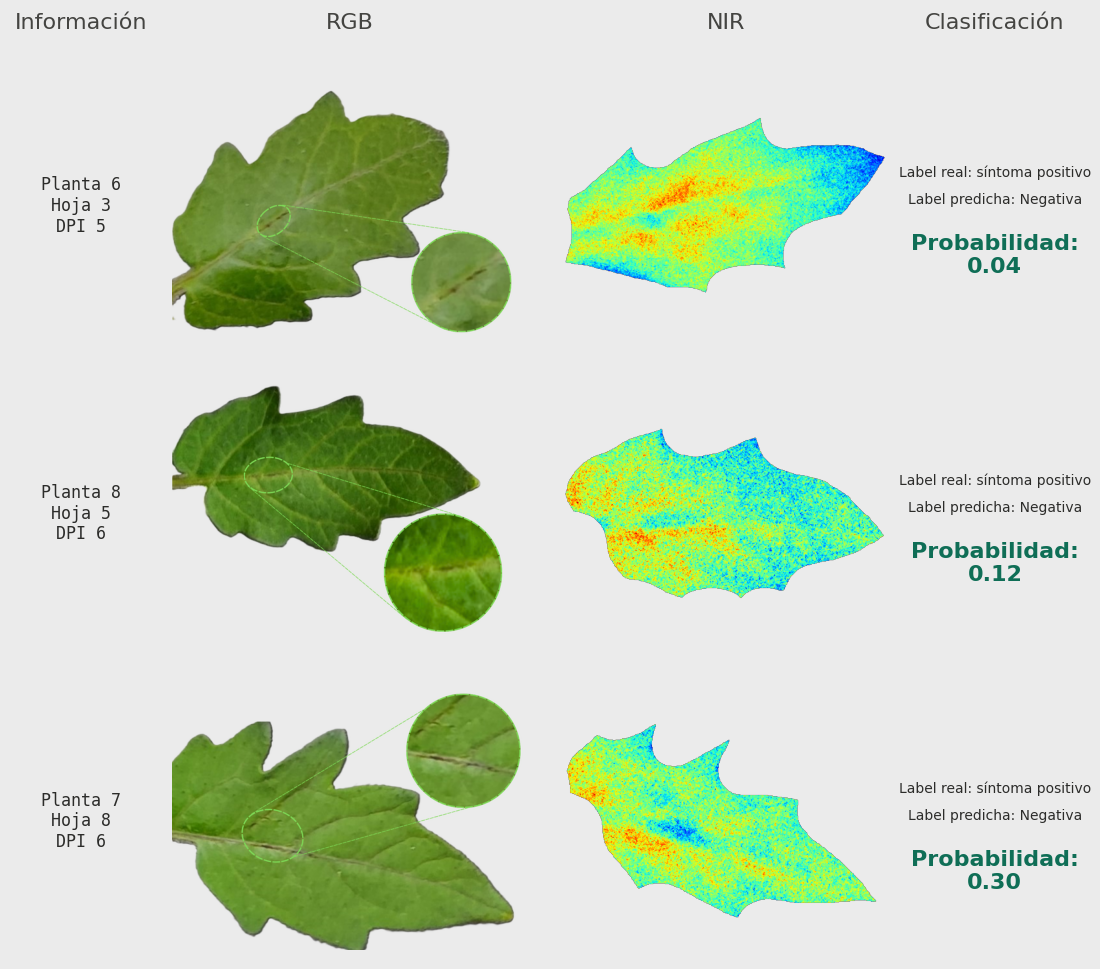

Figura guardada: C:\Users\Bruno\Desktop\TESIS\figuras\predicciones_erradas.png


In [13]:
ejemplos = [
    {'plant_id': 6, 'leaf_id': 3, 'dpi': 5, 'foto_celular': r'C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\26-04\P06_h03_26_04_zoom.png', 'rot' : 0},
    {'plant_id': 8, 'leaf_id': 5, 'dpi': 6, 'foto_celular': r'C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\27-04\P08_h05_27_04_zoom.png', 'rot' : 3},
    {'plant_id': 7, 'leaf_id': 8, 'dpi': 6, 'foto_celular': r'C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\27-04\P07_h08_27_04_zoom.png', 'rot' : 0},
    #{'plant_id': 19, 'leaf_id': 2, 'dpi': 6, 'foto_celular': r'C:\Users\Bruno\Desktop\TESIS\Datos\BATCH1\26-04\P19_h02_26_04_edit.png', 'rot' : 0}
]

predicciones_erradas(ejemplos, df_preds, hojas_procesadas, nombre_archivo=r'C:\Users\Bruno\Desktop\TESIS\figuras\predicciones_erradas.png')

In [61]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

def grafico_evolucion(df_evolucion, hojas_elegidas, hojas_procesadas, features,
                      nombre_archivo='evolucion.png'):
    
    hop_dict = {
        (h['plant_id'], h['leaf_id'], h['dpi']): h
        for h in hojas_procesadas
    }
    
    n = len(hojas_elegidas)
    fig, axes = plt.subplots(n, 1, figsize=(18, 6))
    fig.patch.set_facecolor('#EBEBEB')
    
    if n == 1:
        axes = [axes]
    
    for ax, (plant_id, leaf_id) in zip(axes, hojas_elegidas):
        
        df_hoja = df_evolucion[
            (df_evolucion['plant_id'] == plant_id) &
            (df_evolucion['leaf_id'] == leaf_id)
        ].sort_values('dpi')
        
        dpis = df_hoja['dpi'].values
        probas = df_hoja['y_proba'].values
        tiene_sintoma = df_hoja['y_real'].values
        dpi_sintoma = dpis[tiene_sintoma == 1][0] if tiene_sintoma.sum() > 0 else None
        
        # Linea de proba
        ax.set_facecolor('#EBEBEB')
        ax.plot(dpis, probas, color='#185FA5', linewidth=2, zorder=2)
        ax.scatter(dpis, probas, color='#185FA5', s=40, zorder=3)
        ax.axhline(y=0.5, color='black', linestyle='--', linewidth=0.8, alpha=0.5)
        

        
        ax.set_ylim(-0.05, 1.35)
        ax.set_xlim(dpis[0] - 0.5, dpis[-1] + 0.5)
        ax.set_xticks(dpis)
        ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
        ax.set_ylabel('Probabilidad', fontsize=10)
        ax.set_xlabel('DPI', fontsize=10)
        ax.set_title(f'Planta {plant_id} - Hoja {leaf_id}', fontsize=12, color='#2C2C2A')
        
        ax.tick_params(labelsize=10)
        
        # Imagenes NIR flotantes
        img_h = 0.20  # altura del inset relativa al eje
        img_w = 0.10  # ancho del inset relativa al eje
        
        for j, (dpi, proba) in enumerate(zip(dpis, probas)):
            key = (plant_id, leaf_id, dpi)
            if key not in hop_dict:
                continue
            
            nir = hop_dict[key]['nir']
            nir_plot = nir.copy()
            nir_plot[~hop_dict[key]['mask_hoja']] = np.nan
            
            x_norm = (dpi - (dpis[0] - 0.5)) / ((dpis[-1] + 0.5) - (dpis[0] - 0.5))
            
            offset_base = 0.05 if j % 2 == 0 else 0.10
            y_inset = min(proba + offset_base, 0.70 if j % 2 == 0 else 0.75)
            
            axins = inset_axes(ax, width='100%', height='100%',
                            bbox_to_anchor=(x_norm - img_w/2, y_inset,
                                            img_w, img_h),
                            bbox_transform=ax.transAxes,
                            borderpad=0)
            
            axins.imshow(nir_plot, cmap='jet')
            axins.axis('off')
            
            ax.annotate('', xy=(dpi, proba),
                        xytext=(dpi, y_inset * (ax.get_ylim()[1] - ax.get_ylim()[0]) + ax.get_ylim()[0]),
                        arrowprops=dict(arrowstyle='-', color='gray',
                                    linestyle='dotted', linewidth=0.8))
    
    plt.tight_layout()
    plt.savefig(nombre_archivo, dpi=250, bbox_inches='tight', facecolor='#EBEBEB')
    plt.show()
    print(f'Figura guardada: {nombre_archivo}')

C:\Users\Bruno\AppData\Local\Temp\ipykernel_1696\1208774174.py:83: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


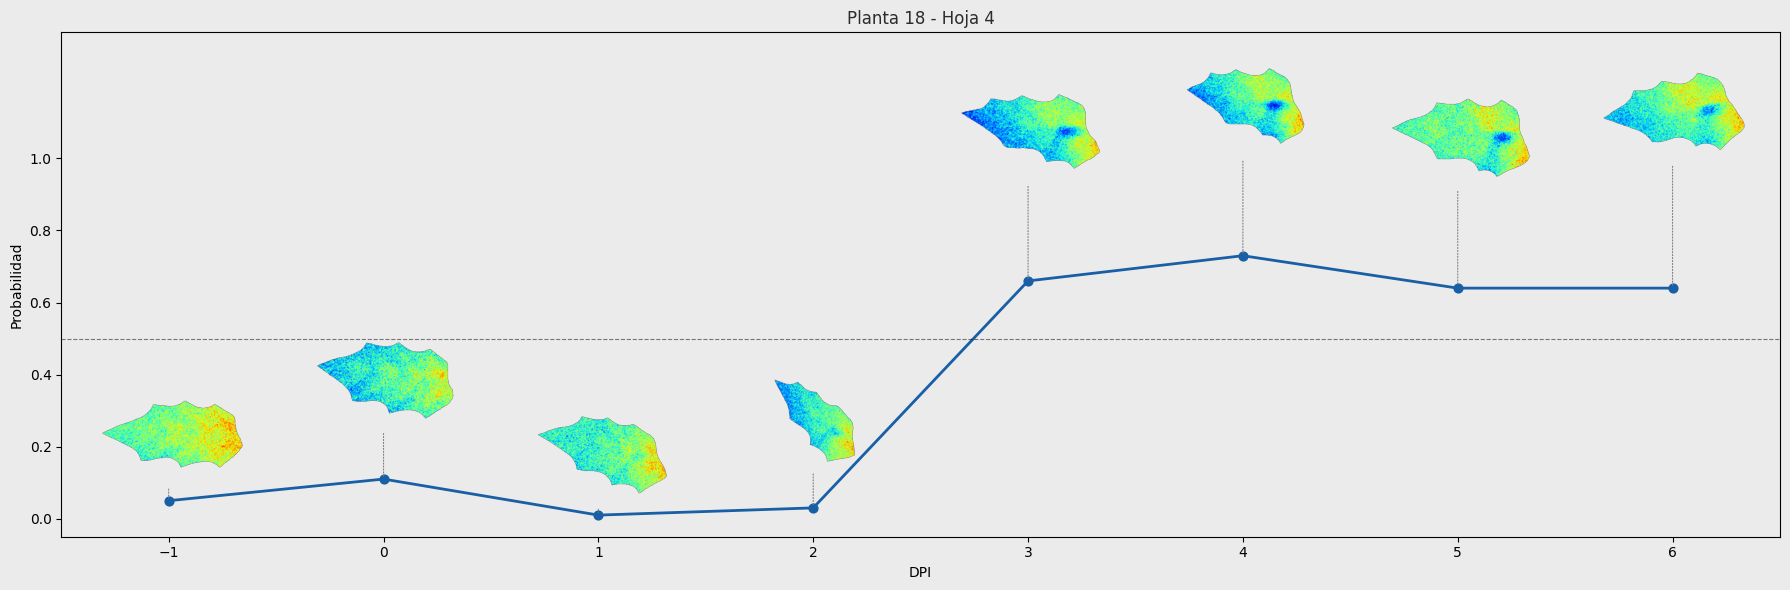

Figura guardada: C:\Users\Bruno\Desktop\TESIS\figuras\evolucion_probas3.png


In [66]:
hojas_elegidas = [(18, 4)]

grafico_evolucion(df_preds, hojas_elegidas, hojas_procesadas,
                  features, nombre_archivo=r'C:\Users\Bruno\Desktop\TESIS\figuras\evolucion_probas3.png')

In [20]:
def lineplot_evolucion_grupos(df_preds, nombre_archivo='evolucion_probas_totales.png'):

    # Identificar hojas con sintoma
    hojas_con_sintoma = set(
        zip(df_preds[df_preds['y_real'] == 1]['plant_id'],
            df_preds[df_preds['y_real'] == 1]['leaf_id'])
    )

    print(df_preds['condition'].unique())
    print(df_preds.groupby(['condition', 'y_real']).size())

    def asignar_grupo(row):
        if (row['plant_id'], row['leaf_id']) in hojas_con_sintoma:
            return 'Síntoma'
        elif row['condition'] in ['Infectada', 'Tratamiento RNA']:
            return 'Infectada sin síntoma'
        else:
            return 'Control'

    df = df_preds.copy()
    df['grupo'] = df.apply(asignar_grupo, axis=1)

    grupos = {
        'Síntoma':                      'firebrick',
        'Infectada sin síntoma': 'seagreen',
        'Control':                           'steelblue'
    }

    fig, ax = plt.subplots(figsize=(14, 6))
    #fig.patch.set_facecolor('#94b0e1')
    #ax.set_facecolor('#94b0e1')

    for grupo, color in grupos.items():
        df_g = df[df['grupo'] == grupo]

        media = df_g.groupby('dpi')['y_proba'].mean()
        std   = df_g.groupby('dpi')['y_proba'].std()
        

        ax.plot(media.index, media.values, color=color,
                linewidth=2, marker='o', markersize=4, label=grupo)
        ax.fill_between(media.index, media.values - std.values, media.values + std.values,
                        color=color, alpha=0.08)
        
        #yerr_low = np.maximum(media.values - p25.values, 0)
        #yerr_high = np.maximum(p75.values - media.values, 0)

        #ax.errorbar(media.index, media.values,
        #            yerr=[yerr_low, yerr_high],
        #            fmt='none', color=color, alpha=0.4, capsize=3, linewidth=1)

    ax.axhline(y=0.5, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
    ax.set_ylim(0, 1)
    ax.set_xlabel('DPI', fontsize=14)
    ax.set_ylabel('Probabilidad', fontsize=14)
    ax.tick_params(labelsize=14)
    legend = ax.legend(fontsize = 14)
    #legend.get_frame().set_facecolor('#94b0e1')  # el color de tu fondo
    #legend.get_frame().set_edgecolor('#94b0e1')  # sin borde visible
    ax.grid(axis='y', linestyle='--', alpha=0.4)

    plt.tight_layout()
    plt.savefig(nombre_archivo, dpi=350, bbox_inches='tight')
    plt.show()
    print(f'Figura guardada: {nombre_archivo}')

['Control' 'Infectada' 'Tratamiento RNA']
condition        y_real
Control          0         179
Infectada        0         136
                 1          52
Tratamiento RNA  0         331
                 1          48
dtype: int64


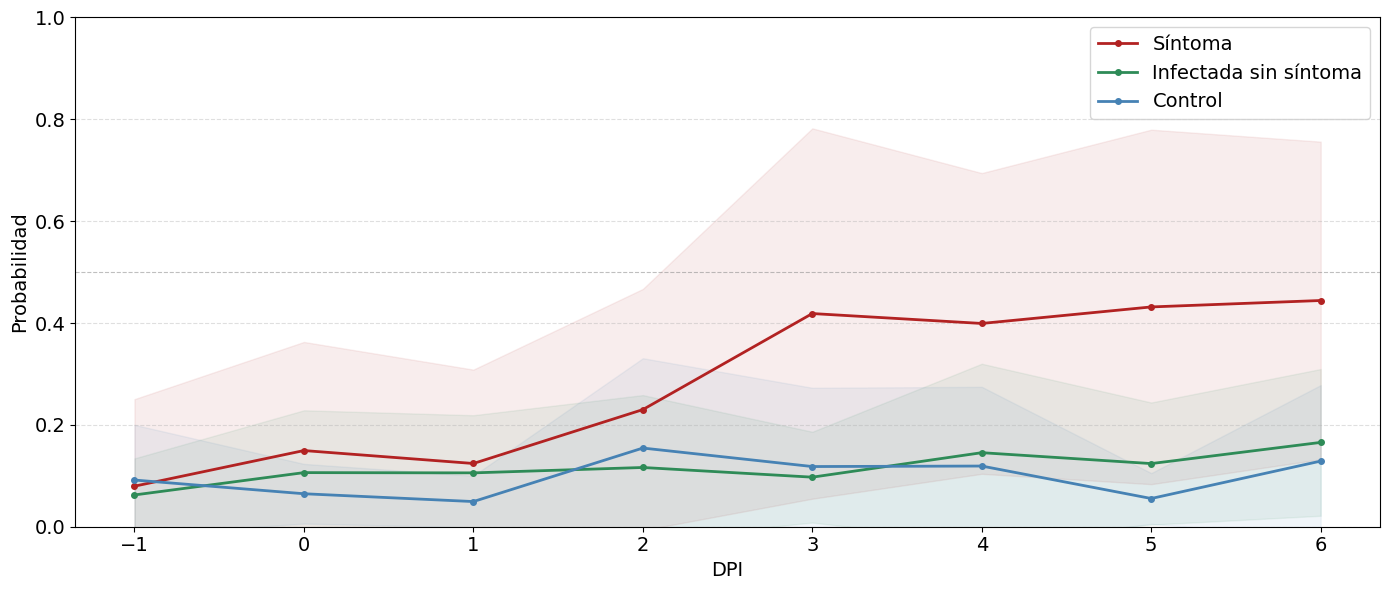

Figura guardada: C:\Users\Bruno\Desktop\TESIS\figuras\evo_probas_tot_poster.png


In [21]:
lineplot_evolucion_grupos(df_preds, nombre_archivo=r'C:\Users\Bruno\Desktop\TESIS\figuras\evo_probas_tot_poster.png')

In [47]:
def lineplot_evolucion_condition(df_preds, nombre_archivo='evolucion_probas_condition.png'):

    print(df_preds['condition'].unique())
    print(df_preds.groupby(['condition', 'y_real']).size())

    df = df_preds.copy()

    grupos = {
        'Control':            'steelblue',
        'Infectada':          'firebrick',
        'Tratamiento RNA':    'seagreen'
    }

    fig, ax = plt.subplots(figsize=(14, 6))

    for grupo, color in grupos.items():
        df_g = df[df['condition'] == grupo]

        media = df_g.groupby('dpi')['y_proba'].mean()
        std   = df_g.groupby('dpi')['y_proba'].std()

        ax.plot(media.index, media.values, color=color,
                linewidth=2, marker='o', markersize=4, label=grupo)
        ax.fill_between(media.index, media.values - std.values, media.values + std.values,
                        color=color, alpha=0.08)

        # --- Anotación del valor final ---
        x_last = media.index[-1]
        y_last = media.values[-1]
        ax.annotate(f"{y_last:.2f}", (x_last, y_last),
                    textcoords="offset points", xytext=(10, 0),
                    fontsize=14, fontweight='bold', color=color,
                    va='center', ha='left')

    ax.axhline(y=0.5, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
    ax.set_ylim(0, 1)
    ax.set_xlim(-1, 6.5)  # un poco más de aire a la derecha para que entre el texto
    ax.set_xlabel('DPI', fontsize=18)
    #ax.set_ylabel('Probabilidad', fontsize=18)
    ax.tick_params(labelsize=15)
    legend = ax.legend(fontsize=12, loc='upper left')
    ax.grid(axis='y', linestyle='--', alpha=0.4)

    plt.tight_layout()
    plt.savefig(nombre_archivo, dpi=350, bbox_inches='tight')
    plt.show()
    print(f'Figura guardada: {nombre_archivo}')

['Control' 'Infectada' 'Tratamiento RNA']
condition        y_real
Control          0         179
Infectada        0         136
                 1          52
Tratamiento RNA  0         331
                 1          48
dtype: int64


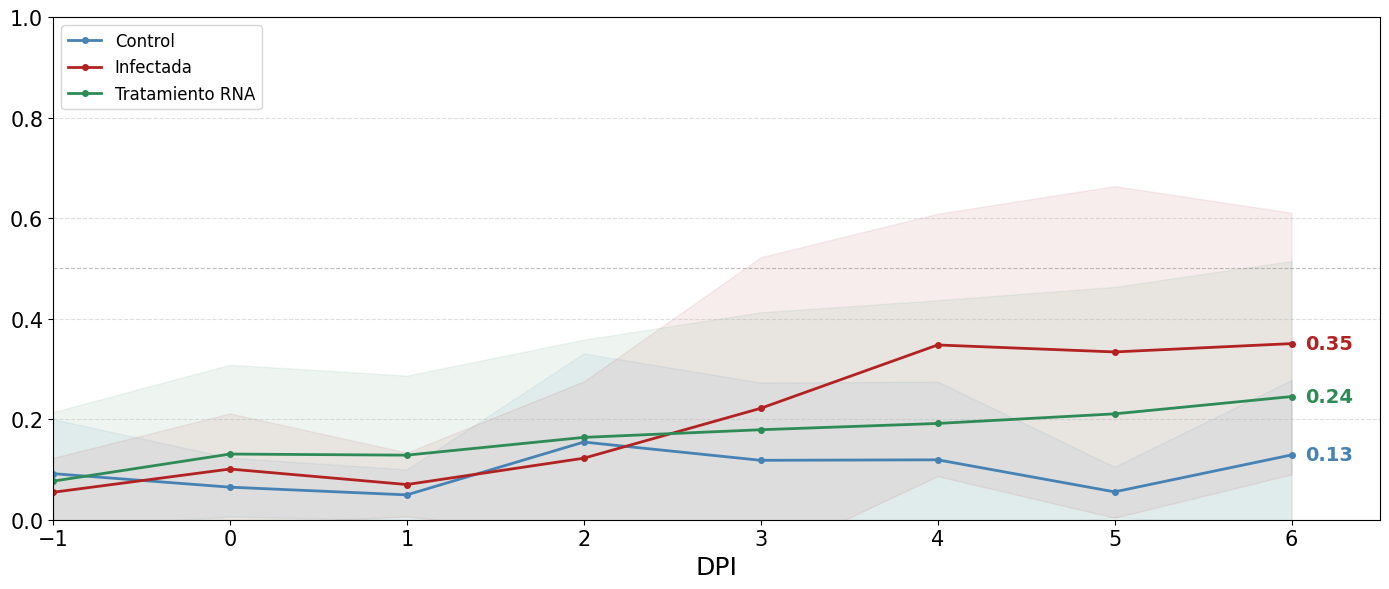

Figura guardada: C:\Users\Bruno\Desktop\TESIS\figuras\evo_probas_tot2_poster.png


In [48]:
lineplot_evolucion_condition(df_preds, nombre_archivo=r'C:\Users\Bruno\Desktop\TESIS\figuras\evo_probas_tot2_poster.png')

In [43]:
from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt

def kaplan_meier_grupos(feats_hojas, nombre_archivo='kaplan_meier.png'):
    
    # Una fila por hoja: tiempo al evento y si ocurrio
    df_hojas = feats_hojas.groupby(['plant_id', 'leaf_id']).apply(
        lambda g: pd.Series({
            'condition': g['condition'].iloc[0],
            'tiempo': g.loc[g['visual'].str.contains('sintoma', na=False), 'dpi'].min()
                    if g['visual'].str.contains('sintoma', na=False).any()
                    else g['dpi'].max(),
            'evento': int(g['visual'].str.contains('sintoma', na=False).any())
        })
    ).reset_index()

    grupos = {
        'Control': 'steelblue',
        'Infectada': 'firebrick',
        'Tratamiento RNA': 'seagreen'
    }

    fig, ax = plt.subplots(figsize=(10, 6))
    #fig.patch.set_facecolor('#EBEBEB')
    #ax.set_facecolor('#EBEBEB')

    kmf = KaplanMeierFitter()

    for grupo, color in grupos.items():
        df_g = df_hojas[df_hojas['condition'] == grupo]
        if len(df_g) == 0:
            continue
        kmf.fit(df_g['tiempo'], event_observed=df_g['evento'], label=grupo)
        kmf.plot_survival_function(ax=ax, color=color, linewidth=2, ci_show=False)

    ax.set_xlabel('DPI', fontsize=12)
    #ax.set_ylabel('Proporción de hojas sanas', fontsize=14)
    ax.tick_params(labelsize=12)
    ax.legend(fontsize=14)
    ax.grid(axis='y', linestyle='--', alpha=0.4)

    plt.tight_layout()
    plt.savefig(nombre_archivo, dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Figura guardada: {nombre_archivo}')

C:\Users\Bruno\AppData\Local\Temp\ipykernel_17936\3950175528.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_hojas = feats_hojas.groupby(['plant_id', 'leaf_id']).apply(


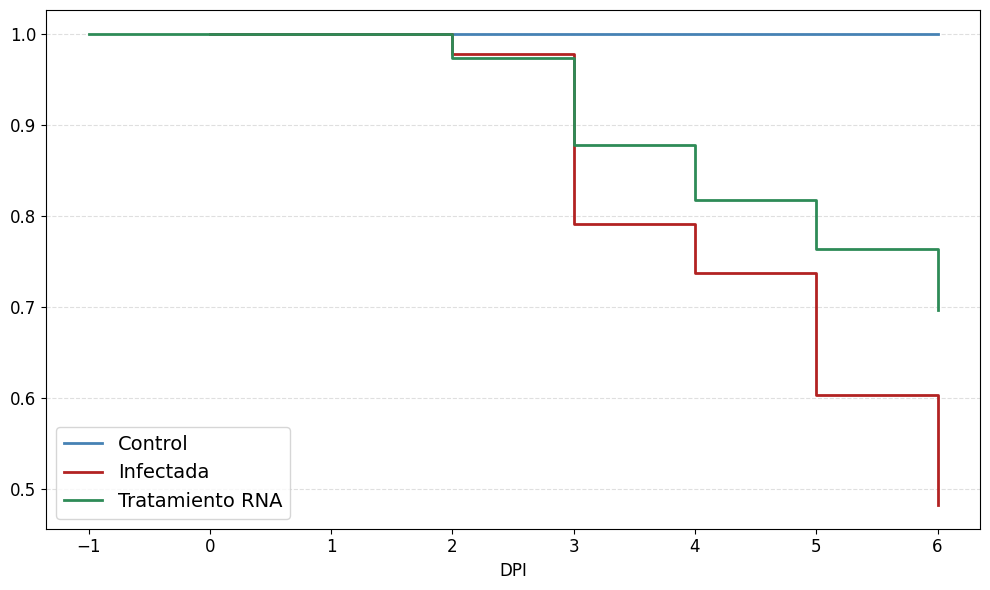

Figura guardada: C:\Users\Bruno\Desktop\TESIS\figuras\curva_kaplan_defensa.png


In [44]:
kaplan_meier_grupos(feats_hojas, nombre_archivo=r'C:\Users\Bruno\Desktop\TESIS\figuras\curva_kaplan_defensa.png')

listo


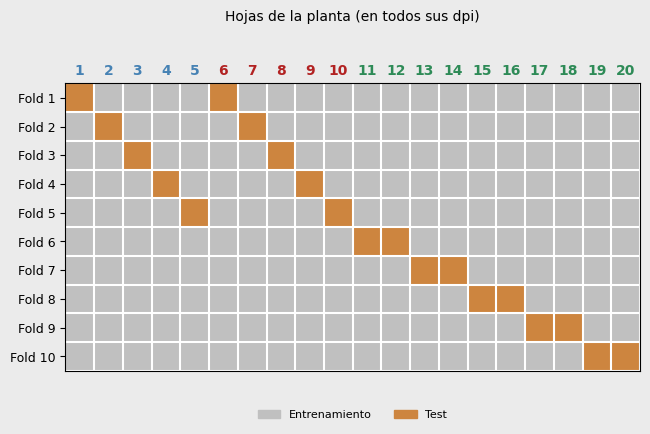

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches

folds = [
    (1, 6), (2, 7), (3, 8), (4, 9), (5, 10),
    (11, 12), (13, 14), (15, 16), (17, 18), (19, 20)
]
n_plants = 20
n_folds = len(folds)

matrix = np.zeros((n_folds, n_plants))
for i, (p1, p2) in enumerate(folds):
    matrix[i, p1-1] = 1
    matrix[i, p2-1] = 1

# condicion por planta: 1-5 control, 6-10 infectada, 11-20 tratamiento
cond_colors_por_planta = (
    ['steelblue'] * 5 +   # control
    ['firebrick'] * 5 +   # infectada
    ['seagreen'] * 10    # tratamiento
)

cell_size = 0.45
fig, ax = plt.subplots(figsize=(n_plants * cell_size, n_folds * cell_size))
fig.patch.set_facecolor('#EBEBEB')
ax.set_facecolor('#EBEBEB')

cmap_colors = ['silver', 'peru']
cmap = ListedColormap(cmap_colors)

ax.imshow(matrix, cmap=cmap, aspect='equal')

# --- ticks mayores: y normal, x vacío (lo dibujamos a mano) ---
ax.set_xticks([])
ax.set_yticks(np.arange(n_folds))
ax.set_yticklabels([f'Fold {i+1}' for i in range(n_folds)], fontsize=9)

# --- numeros de planta coloreados a mano, arriba de la grilla ---
for i, color in enumerate(cond_colors_por_planta):
    ax.text(i, -0.7, str(i+1), ha='center', va='bottom',
             fontsize=10, color=color, fontweight='bold')

ax.set_xlabel('Hojas de la planta (en todos sus dpi)', fontsize=10, labelpad=45)
ax.xaxis.set_label_position('top')

# --- grid (minor ticks): tiene que ir DESPUES de los pasos anteriores ---
ax.set_xticks(np.arange(-0.5, n_plants, 1), minor=True)
ax.set_yticks(np.arange(-0.5, n_folds, 1), minor=True)
ax.grid(which='minor', color='white', linewidth=1.5)
ax.tick_params(which='minor', bottom=False, left=False)

# --- leyenda ---
train_patch = mpatches.Patch(color=cmap_colors[0], label='Entrenamiento')
test_patch = mpatches.Patch(color=cmap_colors[1], label='Test')
#control_patch = mpatches.Patch(color='#4C72B0', label='Control')
#infectada_patch = mpatches.Patch(color='#C44E52', label='Infectada')
#tratamiento_patch = mpatches.Patch(color='#55A868', label='Tratamiento')

ax.legend(handles=[train_patch, test_patch],
          loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=5, frameon=False, fontsize=8)

plt.tight_layout()
plt.savefig(r'C:\Users\Bruno\Desktop\TESIS\figuras\cv_lopo_grilla_defensa.png', dpi=250, bbox_inches='tight')
print("listo")

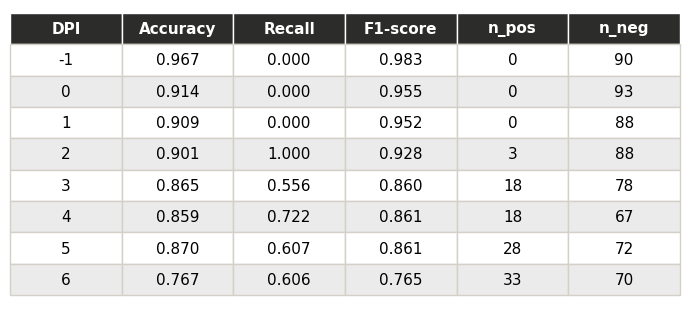

In [8]:
import matplotlib.pyplot as plt
import matplotlib as mpl

data = [
    [-1, 0.967, 0.000, 0.983, 0, 90],
    [0,  0.914, 0.000, 0.955, 0, 93],
    [1,  0.909, 0.000, 0.952, 0, 88],
    [2,  0.901, 1.000, 0.928, 3, 88],
    [3,  0.865, 0.556, 0.860, 18, 78],
    [4,  0.859, 0.722, 0.861, 18, 67],
    [5,  0.870, 0.607, 0.861, 28, 72],
    [6,  0.767, 0.606, 0.765, 33, 70],
]

col_labels = ['DPI', 'Accuracy', 'Recall', 'F1-score', 'n_pos', 'n_neg']

# formatear celdas
cell_text = []
for row in data:
    cell_text.append([
        str(int(row[0])),
        f'{row[1]:.3f}',
        f'{row[2]:.3f}',
        f'{row[3]:.3f}',
        str(int(row[4])),
        str(int(row[5])),
    ])

fig, ax = plt.subplots(figsize=(7, 3.2))
fig.patch.set_facecolor('white')
ax.axis('off')

table = ax.table(
    cellText=cell_text,
    colLabels=col_labels,
    cellLoc='center',
    loc='center'
)

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 1.6)

# estilo header
for j in range(len(col_labels)):
    table[0, j].set_facecolor('#2C2C2A')
    table[0, j].set_text_props(color='white', fontweight='bold')
    table[0, j].set_edgecolor('white')

# estilo filas alternadas
for i in range(1, len(data) + 1):
    for j in range(len(col_labels)):
        if i % 2 == 0:
            table[i, j].set_facecolor('#EBEBEB')
        else:
            table[i, j].set_facecolor('white')
        table[i, j].set_edgecolor('#D3D1C7')

plt.tight_layout()
plt.savefig(r'C:\Users\Bruno\Desktop\TESIS\figuras\metricas.png', dpi=300, bbox_inches='tight')

Listo


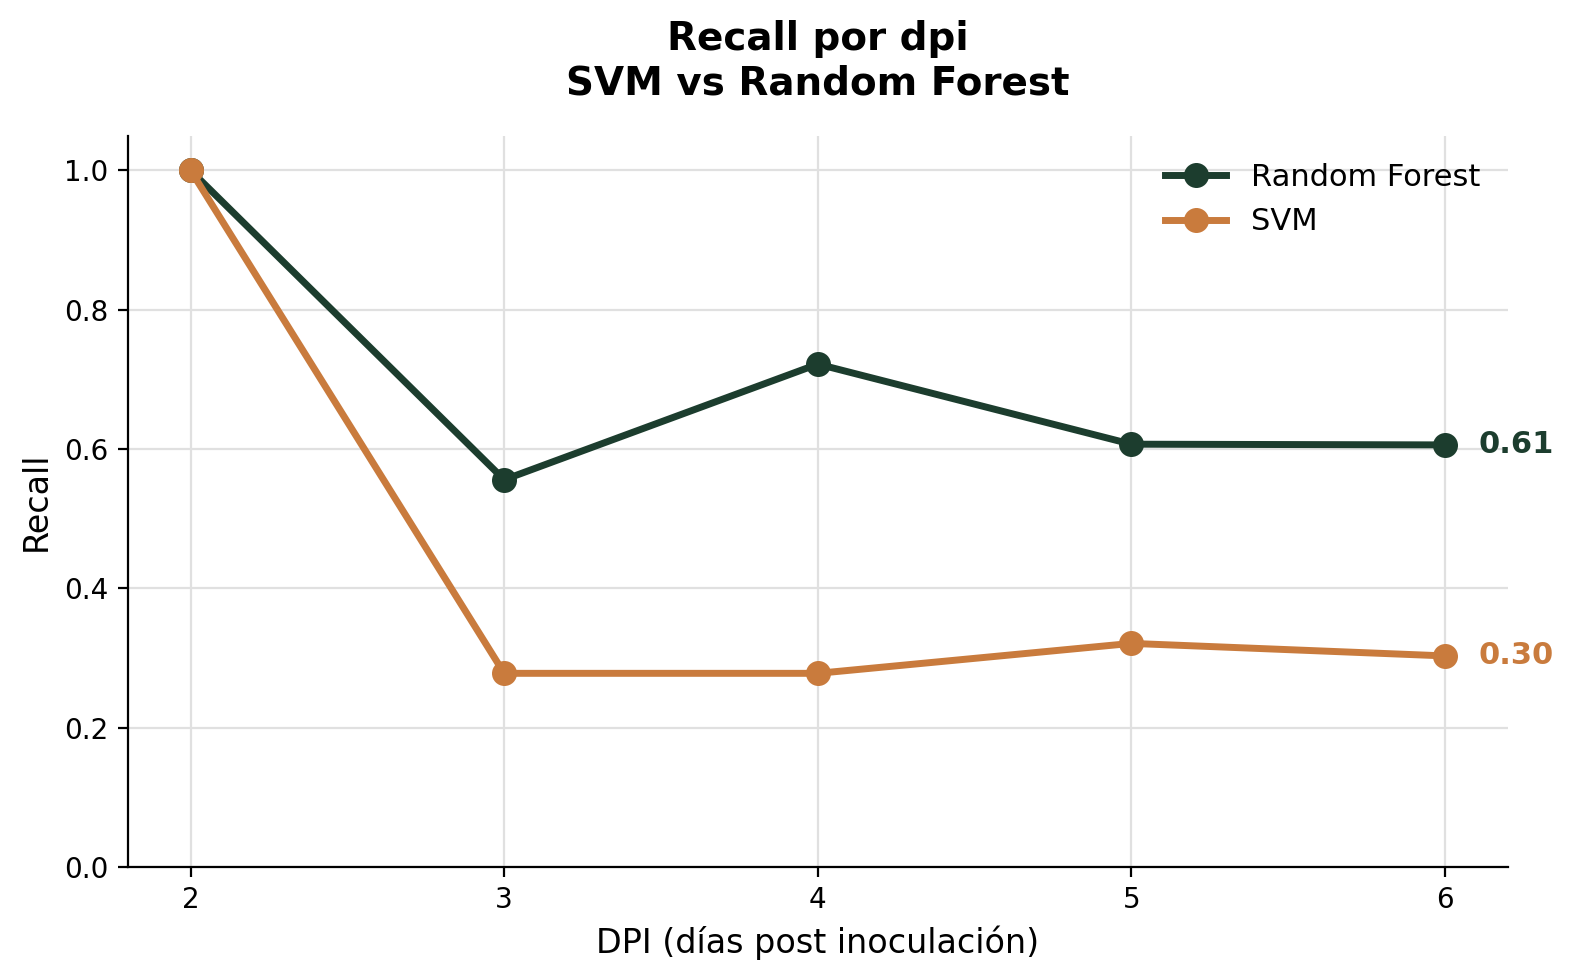

In [3]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# --- Datos extraídos de las Tablas 4.1 (SVM) y 4.2 (RF) de la tesis ---
dpi = [-1, 0, 1, 2, 3, 4, 5, 6]
npos = [0, 0, 0, 3, 18, 18, 28, 33]  # cantidad de hojas positivas por dpi

recall_svm = [0.000, 0.000, 0.000, 1.000, 0.278, 0.278, 0.321, 0.303]
recall_rf  = [0.000, 0.000, 0.000, 1.000, 0.556, 0.722, 0.607, 0.606]

# dpi con npos >= 3 en adelante (a partir de acá el recall es informativo)
# dpi=2 solo tiene 3 positivas, mostramos desde ahí pero con nota
start_idx = 3  # índice de dpi=2

dpi_plot = dpi[start_idx:]
svm_plot = recall_svm[start_idx:]
rf_plot = recall_rf[start_idx:]

# --- Estilo ---
COLOR_RF = "#1c3d2e"     # verde oscuro (mismo del header de las slides)
COLOR_SVM = "#c97b3d"    # naranja/amber, contraste con el verde
BG = "#ffffff"
GRID = "#e0e0e0"

fig, ax = plt.subplots(figsize=(8, 5), dpi=200)
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)

ax.plot(dpi_plot, rf_plot, marker='o', linewidth=2.5, markersize=8,
        color=COLOR_RF, label='Random Forest')
ax.plot(dpi_plot, svm_plot, marker='o', linewidth=2.5, markersize=8,
        color=COLOR_SVM, label='SVM')

# Anotar el valor final de cada curva
ax.annotate(f"{rf_plot[-1]:.2f}", (dpi_plot[-1], rf_plot[-1]),
            textcoords="offset points", xytext=(12, 0), fontsize=11,
            color=COLOR_RF, fontweight='bold', va='center')
ax.annotate(f"{svm_plot[-1]:.2f}", (dpi_plot[-1], svm_plot[-1]),
            textcoords="offset points", xytext=(12, 0), fontsize=11,
            color=COLOR_SVM, fontweight='bold', va='center')

ax.set_xlabel("DPI (días post inoculación)", fontsize=12)
ax.set_ylabel("Recall", fontsize=12)
ax.set_title("Recall por dpi\nSVM vs Random Forest", fontsize=14, fontweight='bold', pad=15)

ax.set_ylim(0, 1.05)
ax.set_xticks(dpi_plot)
ax.grid(True, color=GRID, linewidth=0.8)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.legend(fontsize=11, frameon=False, loc='upper right')

plt.tight_layout()
plt.savefig(r"C:\Users\Bruno\Desktop\TESIS\figuras/recall_svm_vs_rf.png", dpi=300, bbox_inches='tight',
            facecolor=BG)
print("Listo")